# 06 - Systeemevaluatie: hoe goed is het hele systeem op het veld?

In notebook 02 hebben we gemeten hoe goed het detectiemodel is (mAP op afbeeldingen). Dat zegt nog niet of de
**minimap** klopt. Het eindresultaat hangt af van een hele keten: detectie, tracking, de homografie (pixels naar meters),
de teamindeling, de baltracker en de balbezitregel. In dit notebook meten we die keten **als geheel** tegen
**met de hand gelabelde ground truth** (de waarheid, door ons zelf op 28 frames aangeklikt).

**Resultaat in het kort** (finale model `psg_vs_inter_CV.pt`, `imgsz` 1280, baldrempel 0,2; alle cijfers worden verderop in dit notebook berekend):

- **Spelers** worden vrijwel allemaal gevonden: F1 = 0,99 (precisie 0,98, recall 0,99). De rol (PSG, Inter, keeper, scheidsrechter) is bij 99,2 % van de gevonden spelers juist; de enige rolfouten zijn één ID-wissel waarbij een PSG-speler de rol van de scheidsrechter overneemt.
- **Positie in meters**: gemiddeld 1,09 m afwijking van de aangeklikte voetpositie (mediaan 1,03 m, 90 % binnen 1,77 m), gemeten op 6 frames met voetklikken.
- **Bal**: 19 van de 21 gelabelde ballen krijgen een positie (gemiddelde fout 0,7 m, mediaan 0,2 m), maar bij 5 van de 7 frames *zonder* zichtbare bal geeft het systeem toch een bal. Eén gevonden bal ligt 6 m naast de echte.
- **Balbezit**: 21 van de 28 gelabelde frames juist, maar de labels bevatten alleen "PSG heeft de bal". Die maat kan dus niets zeggen over Inter-balbezit en is zwakker dan hij lijkt.
- De varianten (960 of 1280, baldrempel, herdetectie, fine-tuned bal-model) veranderen de spelers-cijfers nauwelijks. Ze verschillen alleen in de **bal**: dat is het zwakke punt van het systeem.

## 0. Voorbereiding

We gebruiken dezelfde code als de Streamlit-app (`streamlit/core`, `streamlit/evaluation`). De pijplijn draait hier met de
**cache** van de detecties: YOLO zelf draait niet opnieuw, we passen enkel de volgende stappen (tracking, homografie, bal, balbezit) toe.
Hierdoor kost een volledige run ongeveer 2 seconden.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display, Markdown

ROOT = Path("..")                                    # de map final_upload
sys.path.insert(0, str(ROOT / "streamlit"))          # de code van de app
import core.pipeline as pipe
from core.paths import DEFAULT_WEIGHTS, MODELS_DIR, VIDEO
from core.video import read_frame
from core.detection import detect
from core.teams import is_person
from core.pipeline import ball_candidate, PITCH_MARGIN, MAX_BALL_SIZE, SPOTS, SPOT_RADIUS
from core import ball_refine
from evaluation.gt_format import load_gt
from evaluation.metrics import evaluate, match_persons, ROLE_OF_GROUP, ROLE_ORDER

%matplotlib inline
warnings.filterwarnings("ignore")
OUT = ROOT / "data" / "results" / "evaluatie"        # resultaatbestanden van dit notebook
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False})
# vaste kleuren: PSG = team A, Inter = team B (kleurenblind-vriendelijk)
COL = {"A": "#0072B2", "B": "#E69F00", "K": "#CC79A7", "R": "#7F7F7F"}
ROLE_NAME = {"A": "PSG", "B": "Inter", "K": "keeper Inter", "R": "scheidsrechter", "other": "overig", "-": "geen"}
GOOD, BAD, NEUTRAL = "#009E73", "#D55E00", "#56B4E9"
pd.set_option("display.width", 160, "display.max_columns", 30)

### Met welk model draait dit notebook?

Alle notebooks gebruiken het **actieve model** `models/psg_vs_inter_CV.pt`. Dat is het meegeleverde referentiemodel, of
het model dat notebook 01 getraind en op die plek gezet heeft. De cel hieronder zegt welk van de twee het is.

In [2]:
# The active model: the delivered reference model, or a model trained and installed by notebook 01.
import hashlib
import json
from pathlib import Path

ACTIVE_MODEL = Path("..") / "models" / "psg_vs_inter_CV.pt"
if not ACTIVE_MODEL.exists():
    raise FileNotFoundError("Er is geen model in models/psg_vs_inter_CV.pt. Draai eerst notebook 01 met een volledige "
                            "training (MODE = 'full', NVIDIA-GPU aanbevolen), of zet het meegeleverde model terug.")
_ref = json.loads((Path("..") / "data" / "results" / "referentie_model.json").read_text(encoding="utf-8"))
IS_REFERENCE = hashlib.md5(ACTIVE_MODEL.read_bytes()).hexdigest() == _ref["md5"]
if IS_REFERENCE:
    print("Actief model: het meegeleverde referentiemodel. De tekst en de cijfers in dit notebook horen bij dit model.")
else:
    print("Actief model: een ANDER model dan het referentiemodel (bijvoorbeeld hertraind in notebook 01).\n"
          "- De code rekent alles opnieuw uit voor dit model.\n"
          "- De begeleidende tekst beschrijft het referentiemodel: de cijfers in de uitvoer kunnen dus van de tekst afwijken.\n"
          "- Zonder detectiecache voor dit model draait YOLO eerst over de clip: seconden op een GPU, minuten per "
          "instelling op een CPU.")

Actief model: het meegeleverde referentiemodel. De tekst en de cijfers in dit notebook horen bij dit model.


## 1. Waarom een aparte systeemevaluatie, en hoe is de ground truth gemaakt?

### Waarom naast de mAP?

De mAP uit notebook 02 meet **per afbeelding** of de boxen kloppen. Voor ons doel is dat niet genoeg:

| Onderdeel van het systeem | Wordt het door de mAP gemeten? |
|---|---|
| Een speler wordt gevonden met een box | ja |
| De teamklasse (PSG, Inter, keeper, scheidsrechter) klopt | gedeeltelijk (per klasse) |
| De homografie zet de voeten op de juiste plaats van het veld | **nee** |
| Spelers die dezelfde track-id behouden in de tijd | **nee** |
| De bal wordt in de tijd gevolgd (gaten ingevuld) en niet bij valse ballen gehouden | **nee** |
| Het balbezit (dichtstbijzijnde speler, gladgestreken) klopt | **nee** |

Fouten kunnen elkaar versterken (een goede box met een slechte homografie geeft een verkeerde meter-positie) of
verbergen (een gemiste bal die de tracker toch invult). Alleen een meting op het **eindresultaat** laat dat zien.

### Hoe de ground truth is gemaakt

Met de labeltool `streamlit/label_ground_truth.py` heeft de eigenaar frames met de hand gelabeld. Per frame wordt
elke persoon aangeklikt (met rol: `A` = PSG, `B` = Inter, `K` = keeper van Inter, `R` = scheidsrechter), de bal wordt
aangeklikt of als "niet zichtbaar" gemarkeerd en het balbezit wordt gekozen (PSG, Inter of niemand). De tool zet de klik meteen
om naar meters met dezelfde homografie als de pijplijn (`data/keypoints.json`). We hebben twee sessies:

| Bestand | Frames | Waar is geklikt? |
|---|---|---|
| `data/ground_truth.json` | 22 frames: elk 30e frame (0, 30, ..., 630) | **op het lichaam** (bij de romp) |
| `data/ground_truth_feet.json` | 6 frames: 0, 120, 240, 360, 480, 600 | **op de voeten** |

De lichaamsklik ging sneller, maar kent een probleem. De homografie is een afbeelding van het **grasvlak**. Een klik op de romp
ligt ongeveer een meter boven dat vlak: de homografie projecteert hem dan op een plek die meters verder op het veld ligt.
Daarom heeft de metriek-code twee **ankers**:

- `anchor="feet"` (voetklik): de klik wordt in **meters** vergeleken met de voetpositie van het systeem. Dit geeft de echte positiefout.
- `anchor="body"` (lichaamsklik): de klik wordt in **pixels** vergeleken met het midden van de box, gedeeld door de boxhoogte (zodat verre en
  nabije spelers gelijk tellen). Detectie, teams en balbezit blijven meetbaar, maar een **positiefout in meters kan hier niet** gemeten worden.

In [3]:
GT_BODY = load_gt(ROOT / "data" / "ground_truth.json")
GT_FEET = load_gt(ROOT / "data" / "ground_truth_feet.json")

def gt_summary(gt, name):
    roles = pd.Series([p["role"] for rec in gt.values() for p in rec["persons"]]).value_counts()
    return {"bestand": name, "frames": len(gt), "personen": int(roles.sum()),
            **{f"{ROLE_NAME[r]}": int(roles.get(r, 0)) for r in ("A", "B", "K", "R")},
            "frames met bal": sum(bool(r["ball_visible"]) for r in gt.values()),
            "frames zonder bal": sum(r["ball_visible"] is False for r in gt.values()),
            "balbezit PSG / Inter / niemand": " / ".join(str(sum(r["possession"] == k for r in gt.values())) for k in ("A", "B", "-"))}

gt_table = pd.DataFrame([gt_summary(GT_BODY, "lichaamsklik"), gt_summary(GT_FEET, "voetklik")]).set_index("bestand")
display(gt_table)

,frames,personen,PSG,Inter,keeper Inter,scheidsrechter,frames met bal,frames zonder bal,balbezit PSG / Inter / niemand
bestand,,,,,,,,,
lichaamsklik,22,516,217,217,22,60,17,5,22 / 0 / 0
voetklik,6,140,60,59,6,15,4,2,6 / 0 / 0


Twee dingen vallen meteen op en komen later terug:

1. In **alle** 28 gelabelde frames is het balbezit "PSG". Er is geen enkel Inter-frame. Een balbezitmetriek op deze labels toetst dus alleen of het systeem PSG-bezit terugziet (zie sectie 2).
2. Beide sessies bevatten frame 0, 120, 240, 360, 480 en 600. Bij frame 360 zegt de lichaamssessie "bal zichtbaar" en de voetsessie "geen bal zichtbaar". De labels spreken elkaar daar tegen, een eerste teken dat de ground truth zelf niet foutloos is.

### Een gelabeld frame

Hieronder frame 120, dat in beide sessies voorkomt: de lichaamsklikken (blauw), de voetklikken (oranje) en de boxen van het systeem (grijs). De uitsnede is vergroot.

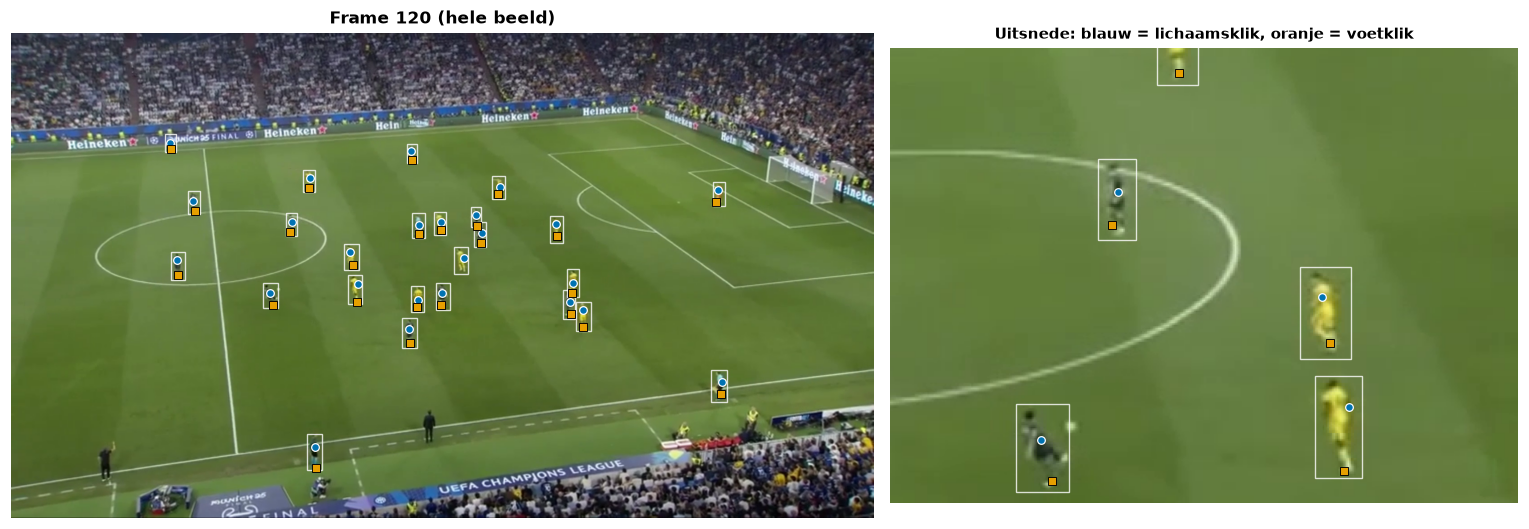

In [4]:
def show_gt_frame(frame_idx, crop, ax):
    # crop = (x0, y0, x1, y1) in pixels
    img = cv2.cvtColor(read_frame(VIDEO, frame_idx), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    for p in result.people[frame_idx]:
        x1, y1, x2, y2 = p["box"]
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white", lw=0.9, alpha=0.8))
    for p in GT_BODY[frame_idx]["persons"]:
        ax.plot(*p["px"], "o", ms=5, mfc="#0072B2", mec="white", mew=0.8)
    for p in GT_FEET[frame_idx]["persons"]:
        ax.plot(*p["px"], "s", ms=5, mfc="#E69F00", mec="black", mew=0.6)
    ax.set_xlim(crop[0], crop[2]); ax.set_ylim(crop[3], crop[1]); ax.axis("off")

result = pipe.run()          # finale instellingen: imgsz 1280, baldrempel 0,2, model psg_vs_inter_CV.pt
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [2.2, 1.6]})
show_gt_frame(120, (0, 0, 1920, 1080), axes[0])
show_gt_frame(120, (480, 330, 880, 620), axes[1])
axes[0].set_title("Frame 120 (hele beeld)"); axes[1].set_title("Uitsnede: blauw = lichaamsklik, oranje = voetklik", fontsize=10)
plt.tight_layout(); plt.show()

De blauwe punten liggen bij de romp, de oranje bij de voeten. Het verschil is enkele tientallen pixels, maar na de projectie naar het veld is dat meters.
We meten het effect: voor elke speler die het systeem terugvindt kijken we **op welke hoogte in zijn box** de klik viel (0 = bovenkant, 1 = onderkant = voeten)
en hoe ver de lichaamsklik in meters van de voetpositie van het systeem ligt.

Hoogte van de klik in de box (0 = hoofd, 1 = voeten): lichaamsklik mediaan 0.40, voetklik mediaan 0.84
Een lichaamsklik, naar meters omgezet, ligt gemiddeld 3.9 m (mediaan 3.9 m) van de voetpositie van het systeem; bij een voetklik is dat 1.09 m.


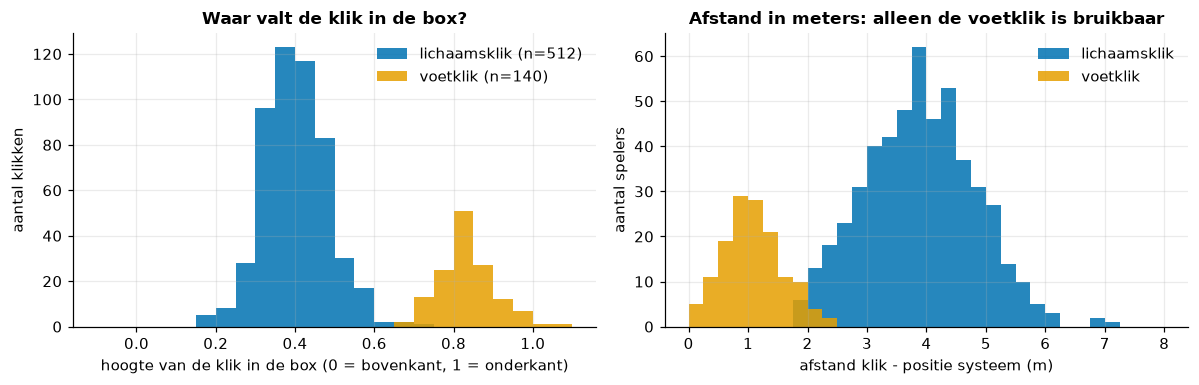

In [5]:
def to_preds(r):
    # pipeline result -> the same structure that evaluation.metrics.load_predictions gives from the csv files
    people = {i: [{"track_id": p["track_id"], "role": ROLE_OF_GROUP.get(p["group"], "other"), "x": p["x_m"], "y": p["y_m"],
                   "box": tuple(p["box"])} for p in r.people[i]] for i in r.ids}
    ball = {i: ((r.ball[i]["x_m"], r.ball[i]["y_m"]) if i in r.ball else None) for i in r.ids}
    poss = {i: r.possession[i]["team"] for i in r.ids}
    return people, ball, poss

preds_people, preds_ball, preds_poss = to_preds(result)

def person_tables(r, gt, anchor, radius):
    # one row per matched pair, per missed person (FN) and per extra prediction (FP)
    people = to_preds(r)[0]
    pairs, fns, fps = [], [], []
    for i, rec in sorted(gt.items()):
        gps, prs = rec["persons"], people[i]
        m = match_persons(gps, prs, radius, anchor)
        used_g, used_p = {a for a, _, _ in m}, {c for _, c, _ in m}
        for a, c, d in m:
            g, p = gps[a], prs[c]
            x1, y1, x2, y2 = p["box"]
            pairs.append({"frame": i, "gt_role": g["role"], "pred_role": p["role"], "dist": d, "track_id": p["track_id"],
                          "gt_px": g["px"], "gt_m": g["m"], "pred_m": (p["x"], p["y"]), "box": p["box"],
                          "box_h": y2 - y1, "click_rel": (g["px"][1] - y1) / max(y2 - y1, 1),
                          "gt_id": g.get("id")})
        fns += [{"frame": i, "role": g["role"], "px": g["px"], "gt_m": g["m"]} for k, g in enumerate(gps) if k not in used_g]
        fps += [{"frame": i, "role": p["role"], "box": p["box"], "pred_m": (p["x"], p["y"]), "track_id": p["track_id"]}
                for k, p in enumerate(prs) if k not in used_p]
    return pd.DataFrame(pairs), pd.DataFrame(fns), pd.DataFrame(fps)

body_pairs, body_fn, body_fp = person_tables(result, GT_BODY, "body", 0.6)
feet_pairs, feet_fn, feet_fp = person_tables(result, GT_FEET, "feet", 3.0)

# hoe ver ligt de lichaamsklik (omgezet naar meters) van de voetpositie van het systeem?
body_pairs["m_dist"] = [np.hypot(g[0] - p[0], g[1] - p[1]) for g, p in zip(body_pairs.gt_m, body_pairs.pred_m)]
print(f"Hoogte van de klik in de box (0 = hoofd, 1 = voeten): lichaamsklik mediaan {body_pairs.click_rel.median():.2f}, "
      f"voetklik mediaan {feet_pairs.click_rel.median():.2f}")
print(f"Een lichaamsklik, naar meters omgezet, ligt gemiddeld {body_pairs.m_dist.mean():.1f} m (mediaan {body_pairs.m_dist.median():.1f} m) "
      f"van de voetpositie van het systeem; bij een voetklik is dat {feet_pairs.dist.mean():.2f} m.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(-0.1, 1.1, 25)
ax[0].hist(body_pairs.click_rel, bins=bins, color=COL["A"], alpha=0.85, label=f"lichaamsklik (n={len(body_pairs)})")
ax[0].hist(feet_pairs.click_rel, bins=bins, color=COL["B"], alpha=0.85, label=f"voetklik (n={len(feet_pairs)})")
ax[0].set_xlabel("hoogte van de klik in de box (0 = bovenkant, 1 = onderkant)"); ax[0].set_ylabel("aantal klikken")
ax[0].set_title("Waar valt de klik in de box?"); ax[0].legend()
ax[1].hist(body_pairs.m_dist, bins=np.linspace(0, 8, 33), color=COL["A"], alpha=0.85, label="lichaamsklik")
ax[1].hist(feet_pairs.dist, bins=np.linspace(0, 8, 33), color=COL["B"], alpha=0.85, label="voetklik")
ax[1].set_xlabel("afstand klik - positie systeem (m)"); ax[1].set_ylabel("aantal spelers")
ax[1].set_title("Afstand in meters: alleen de voetklik is bruikbaar"); ax[1].legend()
plt.tight_layout(); plt.show()

**Wat we zien.** De lichaamsklikken liggen halverwege de box en leveren in meters een afwijking van enkele meters op, puur door het labelen en niet door het systeem.
Daarom gebruiken we de lichaamsklikken (22 frames, 516 personen) voor *detectie, rol en balbezit* in pixelruimte, en de voetklikken (6 frames, 140 personen) voor de *positiefout in meters*.
Dat de sets verschillend zijn is een beperking: de positiefout rust op slechts 6 frames.

## 2. De metrics: uitleg en berekening

Alle metrics komen uit `streamlit/evaluation/metrics.py`; we roepen die functie hier zelf aan op het pijplijnresultaat.

| Metric | Wat is het? | Hoe berekend? |
|---|---|---|
| **Personen gevonden** | Vindt het systeem de mensen op het veld? | Per gelabeld frame koppelt het **Hungaarse algoritme** elke aangeklikte persoon aan hoogstens één box van het systeem, zo dat de totale afstand minimaal is. Een koppeling verder dan de **matchstraal** telt niet. *TP* = gekoppeld, *FN* = aangeklikt maar niet gekoppeld, *FP* = box zonder klik. Precisie = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2TP/(2TP+FP+FN). |
| **Matchstraal** | Hoe ver mag de box van de klik liggen? | voetklik: **3 m**; lichaamsklik: **0,6 boxhoogtes** vanaf het midden van de box |
| **Juiste rol** | Klopt PSG / Inter / keeper / scheidsrechter van de gekoppelde speler? | aandeel gekoppelde spelers waarvan de rol van het systeem gelijk is aan de aangeklikte rol (keeper telt voor het team-cijfer als Inter) |
| **Positiefout (m)** | Hoe ver ligt de voet-positie van de klik? | afstand in meters tussen de voetklik en het midden onderaan de box na projectie. We tonen de **verdeling**, niet alleen het gemiddelde |
| **Bal gevonden** | Heeft het systeem in een frame met zichtbare bal een positie? | `ball_state` is `detected`, `interpolated` of `refined`. Een ingevulde (geïnterpoleerde) bal telt dus mee |
| **Balfout (m)** | Hoe ver ligt die positie van de aangeklikte bal? | afstand in meters. Een fout boven 3 m rekenen we als "op de verkeerde plek" |
| **Valse bal** | Geeft het systeem een bal als er geen is? | aandeel van de frames waarin de labelaar "geen bal zichtbaar" koos en het systeem toch een bal heeft |
| **Balbezit juist** | Klopt het team met balbezit? | aandeel frames waarin het gladgestreken balbezit gelijk is aan het gelabelde (PSG, Inter of niemand) |
| **ID-wissels** | Behoudt een speler zijn track-id? | zie de beperking in sectie 6: niet betrouwbaar meetbaar met frames die 1 s uit elkaar liggen |

In [6]:
res_body = evaluate(GT_BODY, preds_people, preds_ball, preds_poss, anchor="body")
res_feet = evaluate(GT_FEET, preds_people, preds_ball, preds_poss, anchor="feet")

def fmt(v, nd=3):
    return "n.v.t." if v is None else f"{v:.{nd}f}"

rows = []
for label, key in (("gelabelde frames", None),):
    rows.append({"maat": "gelabelde frames", "lichaamsklik (22 frames)": res_body["model_frames"]["matched"], "voetklik (6 frames)": res_feet["model_frames"]["matched"]})
for name, getter in (
    ("personen: TP / FP / FN", lambda r: f"{r['players']['tp']} / {r['players']['fp']} / {r['players']['fn']}"),
    ("precisie", lambda r: fmt(r["players"]["precision"])), ("recall", lambda r: fmt(r["players"]["recall"])),
    ("F1", lambda r: fmt(r["players"]["f1"])),
    ("juiste rol", lambda r: fmt(r["teams"]["role_accuracy"])),
    ("positiefout gemiddeld (m)", lambda r: fmt(r["players"]["position_error_m"]["mean"], 2)),
    ("positiefout mediaan (m)", lambda r: fmt(r["players"]["position_error_m"]["median"], 2)),
    ("positiefout 90e percentiel (m)", lambda r: fmt(r["players"]["position_error_m"]["p90"], 2)),
    ("afstand klik-box (boxhoogtes), mediaan", lambda r: fmt(r["players"]["match_distance_box_heights"]["median"])),
    ("bal: frames met bal / gevonden", lambda r: f"{r['ball']['frames_with_ball']} / {round(r['ball']['frames_with_ball'] * r['ball']['detection_rate'])}"),
    ("balfout gemiddeld / mediaan (m)", lambda r: f"{fmt(r['ball']['position_error_m']['mean'], 2)} / {fmt(r['ball']['position_error_m']['median'], 2)}"),
    ("bal binnen 3 m van de klik", lambda r: fmt(r["ball"]["within_3m"])),
    ("frames zonder bal / met valse bal", lambda r: f"{r['ball']['frames_without_ball']} / {round(r['ball']['frames_without_ball'] * r['ball']['false_ball_rate'])}"),
    ("balbezit juist", lambda r: fmt(r["possession"]["accuracy"])),
    ("ID-wissels (zie sectie 6)", lambda r: str(r["tracking"]["id_switches"])),
    ("IDF1-lite (zie sectie 6)", lambda r: fmt(r["tracking"]["idf1_lite"])),
):
    rows.append({"maat": name, "lichaamsklik (22 frames)": getter(res_body), "voetklik (6 frames)": getter(res_feet)})
metrics_table = pd.DataFrame(rows).set_index("maat").replace({"n.v.t.": "-"})
display(metrics_table)
metrics_table.to_csv(OUT / "metrics_finaal.csv")

# controle: F1 met de hand uit TP/FP/FN
tp, fp, fn = res_body["players"]["tp"], res_body["players"]["fp"], res_body["players"]["fn"]
print(f"Controle F1 (lichaamsklik) met de hand: 2*{tp} / (2*{tp} + {fp} + {fn}) = {2 * tp / (2 * tp + fp + fn):.4f}")

,lichaamsklik (22 frames),voetklik (6 frames)
maat,,
gelabelde frames,22,6
personen: TP / FP / FN,512 / 11 / 4,140 / 3 / 0
precisie,0.979,0.979
recall,0.992,1.000
F1,0.986,0.989
juiste rol,0.992,0.993
positiefout gemiddeld (m),-,1.09
positiefout mediaan (m),-,1.03
positiefout 90e percentiel (m),-,1.77


Controle F1 (lichaamsklik) met de hand: 2*512 / (2*512 + 11 + 4) = 0.9856


Een eerste lezing:

- **Spelers**: slechts 4 gemiste personen op 516 en 11 boxen zonder klik. In sectie 5 bekijken we elk van die gevallen.
- **De rol** van de gevonden spelers klopt bijna altijd. Dat is een gevolg van het fine-tunen: het model kent PSG, Inter, keeper en scheidsrechter als aparte klassen.
- De **positiefout** (1,09 m gemiddeld) is een eindresultaat van detectie, voeten-schatting en homografie samen. We bekijken nu de verdeling.

### Verdeling van de positiefout

Een gemiddelde verbergt uitschieters. Daarom een histogram, de cumulatieve verdeling en een uitsplitsing per rol (alleen voetklikken, n = 140).

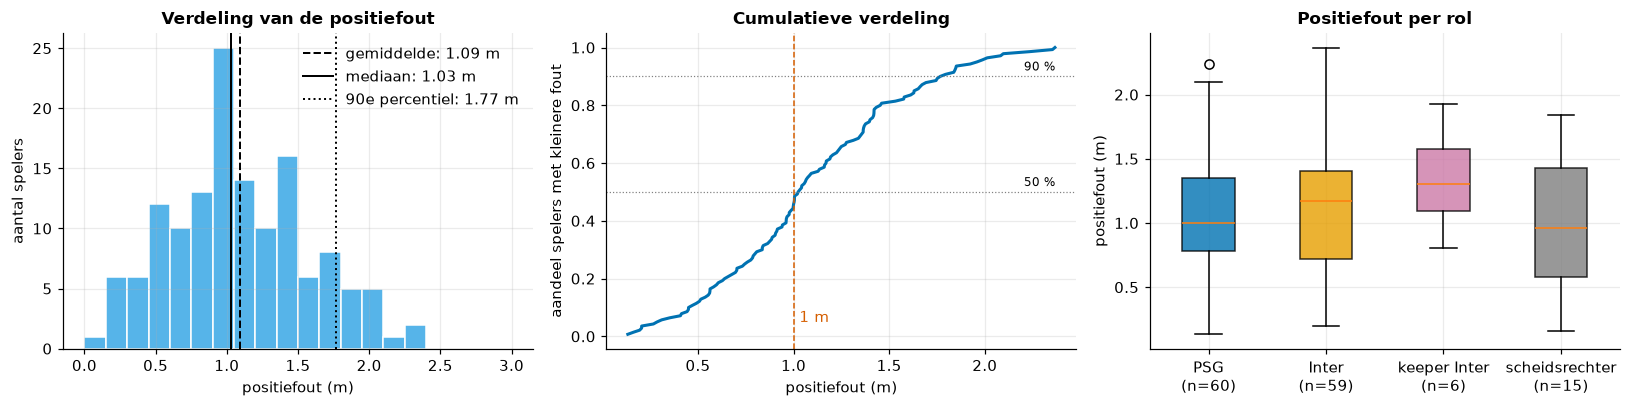

Aandeel binnen 0,5 m / 1 m / 2 m: ['11%', '46%', '96%'] | grootste fout: 2.37 m


In [7]:
err = feet_pairs.dist.to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(err, bins=np.arange(0, 3.01, 0.15), color=NEUTRAL, ec="white")
for v, name, ls in ((err.mean(), "gemiddelde", "--"), (np.median(err), "mediaan", "-"), (np.percentile(err, 90), "90e percentiel", ":")):
    ax[0].axvline(v, color="black", ls=ls, lw=1.3, label=f"{name}: {v:.2f} m")
ax[0].set_xlabel("positiefout (m)"); ax[0].set_ylabel("aantal spelers"); ax[0].set_title("Verdeling van de positiefout"); ax[0].legend()
xs = np.sort(err); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=COL["A"], lw=2)
for q in (0.5, 0.9):
    ax[1].axhline(q, color="grey", lw=0.8, ls=":"); ax[1].text(xs.max(), q + 0.01, f"{int(q * 100)} %", ha="right", va="bottom", fontsize=8)
ax[1].axvline(1.0, color=BAD, lw=1, ls="--"); ax[1].text(1.03, 0.05, "1 m", color=BAD)
ax[1].set_xlabel("positiefout (m)"); ax[1].set_ylabel("aandeel spelers met kleinere fout"); ax[1].set_title("Cumulatieve verdeling")
groups = [(r, feet_pairs.loc[feet_pairs.gt_role == r, "dist"].to_numpy()) for r in ("A", "B", "K", "R")]
bp = ax[2].boxplot([g for _, g in groups], patch_artist=True, showfliers=True)
ax[2].set_xticklabels([f"{ROLE_NAME[r]}\n(n={len(g)})" for r, g in groups])
for patch, (r, _) in zip(bp["boxes"], groups):
    patch.set_facecolor(COL[r]); patch.set_alpha(0.8)
ax[2].set_ylabel("positiefout (m)"); ax[2].set_title("Positiefout per rol")
plt.tight_layout(); plt.show()
print("Aandeel binnen 0,5 m / 1 m / 2 m:", [f"{(err <= t).mean():.0%}" for t in (0.5, 1, 2)], "| grootste fout:", f"{err.max():.2f} m")

**Wat we zien.** De fout is geen uitschieter-verhaal: bijna de helft van de spelers ligt binnen 1 m en 96 % binnen 2 m; de grootste fout is 2,4 m. Dat is ongeveer de ruimte die een voet inneemt plus de onzekerheid van de homografie (de keypoints zijn met de hand geklikt; zie notebook 03).
Een systematisch verschil tussen de rollen is er niet; de keeper en scheidsrechter hebben weinig punten, dus daar is de spreiding groot.

### Gevoeligheid voor de matchstraal

De matchstraal is een keuze (3 m voor voeten, 0,6 boxhoogte voor lichaam). Als F1 sterk afhangt van die keuze is de metriek zwak. We laten de straal variëren.

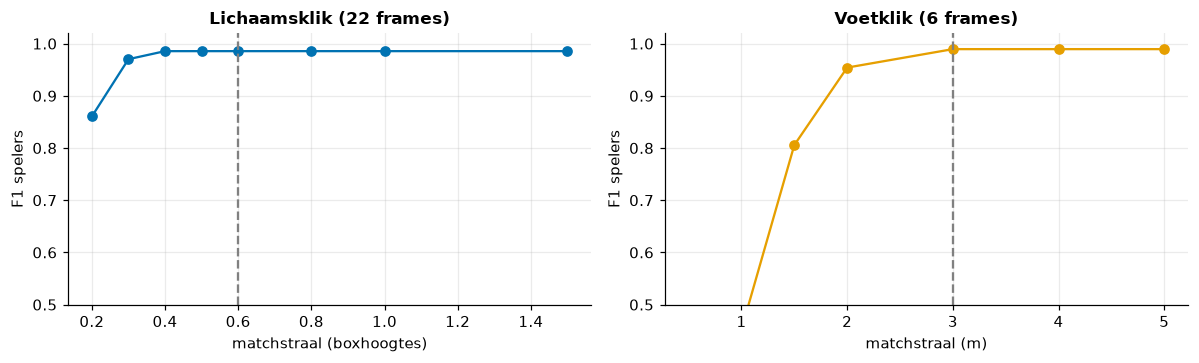

straal (boxhoogtes)  0.20  0.30  0.400  0.500  0.600  0.800  1.000  1.500
F1                   0.86  0.97  0.986  0.986  0.986  0.986  0.986  0.986
straal (m)  0.500  1.000  1.500  2.000  3.000  4.000  5.000
F1          0.113  0.452  0.806  0.954  0.989  0.989  0.989


In [8]:
radii_body = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5]
radii_feet = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0]
f1_body = [evaluate(GT_BODY, preds_people, preds_ball, preds_poss, anchor="body", radius=r)["players"]["f1"] for r in radii_body]
f1_feet = [evaluate(GT_FEET, preds_people, preds_ball, preds_poss, anchor="feet", radius=r)["players"]["f1"] for r in radii_feet]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(radii_body, f1_body, "o-", color=COL["A"]); ax[0].axvline(0.6, color="grey", ls="--"); ax[0].set_xlabel("matchstraal (boxhoogtes)")
ax[0].set_ylabel("F1 spelers"); ax[0].set_title("Lichaamsklik (22 frames)")
ax[1].plot(radii_feet, f1_feet, "o-", color=COL["B"]); ax[1].axvline(3.0, color="grey", ls="--"); ax[1].set_xlabel("matchstraal (m)")
ax[1].set_ylabel("F1 spelers"); ax[1].set_title("Voetklik (6 frames)")
for a in ax: a.set_ylim(0.5, 1.02)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"straal (boxhoogtes)": radii_body, "F1": np.round(f1_body, 3)}).T.to_string(header=False))
print(pd.DataFrame({"straal (m)": radii_feet, "F1": np.round(f1_feet, 3)}).T.to_string(header=False))

**Wat we zien.** Bij de lichaamsklik is F1 stabiel vanaf 0,4 boxhoogte: de gekozen 0,6 ligt op het vlakke deel. Bij de voetklik is dat **niet** zo. Omdat de typische positiefout ongeveer 1 m is, zou bij een straal van 1 m maar 45 % van de spelers worden gekoppeld (F1 0,45) en bij 2 m is F1 0,95. Pas vanaf 3 m is de F1 vlak (0,989). De "F1 van 0,99 voor spelers" is dus een uitspraak over *gevonden binnen 3 m*, en dat is ruim. Daarom rapporteren we de positiefout in meters apart en stellen de F1 niet voor als maat voor de nauwkeurigheid van de positie.

### Rol-verwarringsmatrix

Hoe vaak krijgt een persoon een andere rol dan de labelaar koos? Rijen = aangeklikte rol, kolommen = rol van het systeem.

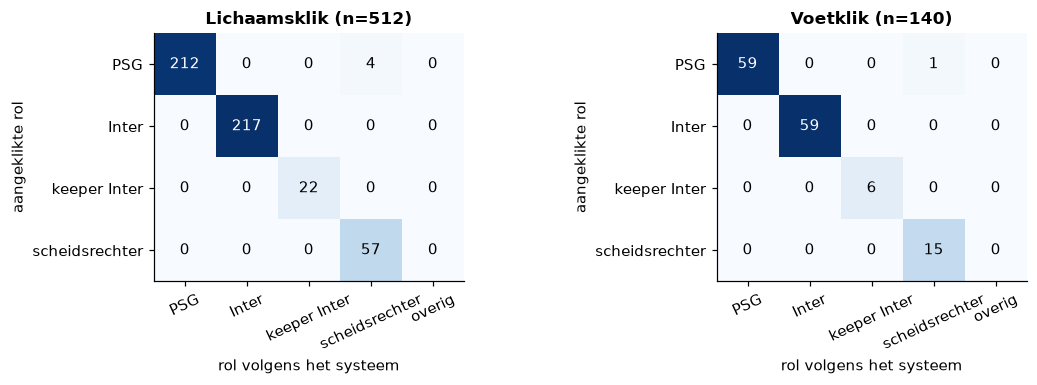

,sessie,frame,gt_role,pred_role,track_id
0,lichaam,540,A,R,6
1,lichaam,570,A,R,6
2,lichaam,600,A,R,6
3,lichaam,630,A,R,6
4,voet,600,A,R,6


In [9]:
def confusion(pairs):
    cm = pd.crosstab(pairs.gt_role, pairs.pred_role).reindex(index=["A", "B", "K", "R"], columns=ROLE_ORDER, fill_value=0)
    return cm

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
for a, pairs, title in ((ax[0], body_pairs, "Lichaamsklik (n=512)"), (ax[1], feet_pairs, "Voetklik (n=140)")):
    cm = confusion(pairs)
    a.imshow(cm.values, cmap="Blues", vmin=0, vmax=cm.values.max())
    a.set_xticks(range(len(cm.columns))); a.set_xticklabels([ROLE_NAME[c] for c in cm.columns], rotation=25)
    a.set_yticks(range(len(cm.index))); a.set_yticklabels([ROLE_NAME[c] for c in cm.index]); a.grid(False)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            a.text(j, i, cm.values[i, j], ha="center", va="center", color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
    a.set_xlabel("rol volgens het systeem"); a.set_ylabel("aangeklikte rol"); a.set_title(title)
plt.tight_layout(); plt.show()
wrong = pd.concat([body_pairs.assign(sessie="lichaam"), feet_pairs.assign(sessie="voet")]).query("gt_role != pred_role")
display(wrong[["sessie", "frame", "gt_role", "pred_role", "track_id"]].reset_index(drop=True))

**Wat we zien.** Op de diagonaal staat bijna alles. De enige verwarring is dat een PSG-speler als scheidsrechter is bestempeld (4 keer in de lichaamsset, 1 keer in de voetset). Alle vijf de fouten hebben dezelfde track-id (6): het gaat om **één speler** in de laatste vier seconden van de clip, en niet om vijf losse fouten. Wat daar gebeurt bekijken we in sectie 5.3.

### Bal en balbezit

We gebruiken beide sessies samen: 28 frames, waarvan 21 met zichtbare bal en 7 zonder. Per gelabeld frame bepalen we de uitkomst:

- **goed**: bal gelabeld en het systeem geeft een bal binnen 3 m;
- **verkeerde plek**: het systeem geeft een bal verder dan 3 m weg;
- **gemist**: bal gelabeld, het systeem geeft geen bal;
- **valse bal**: "geen bal zichtbaar" gelabeld, het systeem geeft toch een bal;
- **terecht geen bal**.

In [10]:
def ball_table(r, session_gt):
    # one row per labelled frame with the outcome of the ball
    rows = []
    for session, gt in session_gt.items():
        for i, rec in sorted(gt.items()):
            gb, pb = rec.get("ball"), r.ball.get(i)
            row = {"sessie": session, "frame": i, "gt_zichtbaar": bool(rec["ball_visible"]), "gt_px": gb["px"] if gb else None,
                   "gt_m": tuple(gb["m"]) if gb else None, "status": pb["state"] if pb else "none",
                   "pred_m": (pb["x_m"], pb["y_m"]) if pb else None, "conf": pb["conf"] if pb else None}
            if rec["ball_visible"] and gb:
                row["fout_m"] = float(np.hypot(pb["x_m"] - gb["m"][0], pb["y_m"] - gb["m"][1])) if pb else np.nan
                row["uitkomst"] = "gemist" if not pb else ("goed" if row["fout_m"] <= 3 else "verkeerde plek")
            else:
                row["fout_m"] = np.nan
                row["uitkomst"] = "valse bal" if pb else "terecht geen bal"
            rows.append(row)
    return pd.DataFrame(rows)

SESSIONS = {"lichaam": GT_BODY, "voet": GT_FEET}
ball_tab = ball_table(result, SESSIONS)
summary = ball_tab.groupby(["sessie", "uitkomst"]).size().unstack(fill_value=0)
summary.loc["samen"] = summary.sum()
display(summary)
good = ball_tab[ball_tab.uitkomst == "goed"].fout_m
print(f"Balfout van de goede ballen (n={len(good)}): gemiddeld {good.mean():.2f} m, mediaan {good.median():.2f} m, maximum {good.max():.2f} m")
print("Status van de gevonden ballen:", ball_tab[ball_tab.uitkomst == "goed"].status.value_counts().to_dict())
found_all = ball_tab[ball_tab.fout_m.notna()].fout_m
print(f"Alle gevonden ballen (n={len(found_all)}, ook die op de verkeerde plek): gemiddeld {found_all.mean():.2f} m, mediaan {found_all.median():.2f} m")
ball_tab.to_csv(OUT / "bal_per_frame.csv", index=False)

uitkomst,gemist,goed,terecht geen bal,valse bal,verkeerde plek
sessie,,,,,
lichaam,2,14,1,4,1
voet,0,4,1,1,0
samen,2,18,2,5,1


Balfout van de goede ballen (n=18): gemiddeld 0.39 m, mediaan 0.22 m, maximum 1.56 m
Status van de gevonden ballen: {'detected': 11, 'interpolated': 7}
Alle gevonden ballen (n=19, ook die op de verkeerde plek): gemiddeld 0.69 m, mediaan 0.23 m


**Wat we zien.** Een bal binnen 3 m wordt 18 keer van de 21 gelabelde ballen goed teruggegeven; 2 zijn gemist en 1 ligt op de verkeerde plek (6 m ernaast). Zeven van de 18 goede ballen zijn **ingevuld** door de tracker (`interpolated`) en niet rechtstreeks door YOLO gezien. Dat is bedoeld (de bal is ~10 pixels groot en wordt tussen detecties door voorspeld), maar het betekent ook dat het systeem een bal "weet" in frames waar YOLO niets zag.
De keerzijde staat in het rechtergedeelte van de tabel: de **valse bal** is het grootste bal-probleem (5 van de 7 frames zonder zichtbare bal). In sectie 5 zoeken we uit waarom.

### Balbezit

Het balbezit is de dichtstbijzijnde speler binnen 2 m van de bal, gladgestreken (pas wisselen na 5 frames). We vergelijken met de labels.

In [11]:
poss_rows = []
for session, gt in SESSIONS.items():
    for i, rec in sorted(gt.items()):
        poss_rows.append({"sessie": session, "frame": i, "gt": rec["possession"], "systeem": preds_poss[i]})
poss_tab = pd.DataFrame(poss_rows)
display(pd.crosstab(poss_tab["gt"].map({"A": "gelabeld: PSG"}), poss_tab.systeem.map({"A": "systeem: PSG", "B": "systeem: Inter", "-": "systeem: niemand"})))
n_ok = int((poss_tab["gt"] == poss_tab.systeem).sum())
print(f"Juist: {n_ok} van {len(poss_tab)} ({n_ok / len(poss_tab):.0%}). Een systeem dat altijd 'PSG' zegt zou op deze labels {len(poss_tab)} van {len(poss_tab)} halen.")
print(f"Over de hele clip geeft het systeem balbezit aan PSG in {pipe.possession_share(result)['A']:.0f} % van de frames met balbezit.")

systeem,systeem: Inter,systeem: PSG,systeem: niemand
gt,,,
gelabeld: PSG,1,21,6


Juist: 21 van 28 (75%). Een systeem dat altijd 'PSG' zegt zou op deze labels 28 van 28 halen.
Over de hele clip geeft het systeem balbezit aan PSG in 92 % van de frames met balbezit.


**Wat we zien.** De "juiste" 75 % is **geen goede score**: omdat de labels alleen PSG bevatten, haalt een systeem dat altijd "PSG" zegt 100 %. De 7 fouten zijn frames waarin het systeem "niemand" (6x) of Inter (1x) zegt. De metriek meet hier dus eigenlijk hoe vaak het systeem het balbezit **mist**, niet of het de teams kan onderscheiden. Een eerlijke balbezitmeting vraagt labels van beide teams (zie Beperkingen).

### ID-wissels

De labeltool geeft elke persoon een id, dus de metriek kan tellen hoe vaak de track-id van een gekoppelde speler tussen twee gelabelde frames verandert. De cijfers staan in de tabel hierboven (71 wissels bij 66 personen in de lichaamsset). **We gebruiken ze niet als maat.** De gelabelde frames liggen 30 frames (1 s) uit elkaar en spelers verplaatsen zich in die tijd meters; de labeltool geeft bovendien alleen dezelfde id als iemand binnen 5 m van zijn vorige positie wordt aangeklikt. Elke fout van de labelaar telt dus mee als een wissel van het systeem. Om ID-wissels echt te meten zijn aaneengesloten gelabelde frames nodig (bijvoorbeeld 30 frames op rij).

## 3. Resultaten per frame: waar gaat het mis?

Eerst per gelabeld frame het aantal gemiste personen (FN) en extra boxen (FP) in de lichaamsset. Daarna de fout als functie van de plaats op het veld.

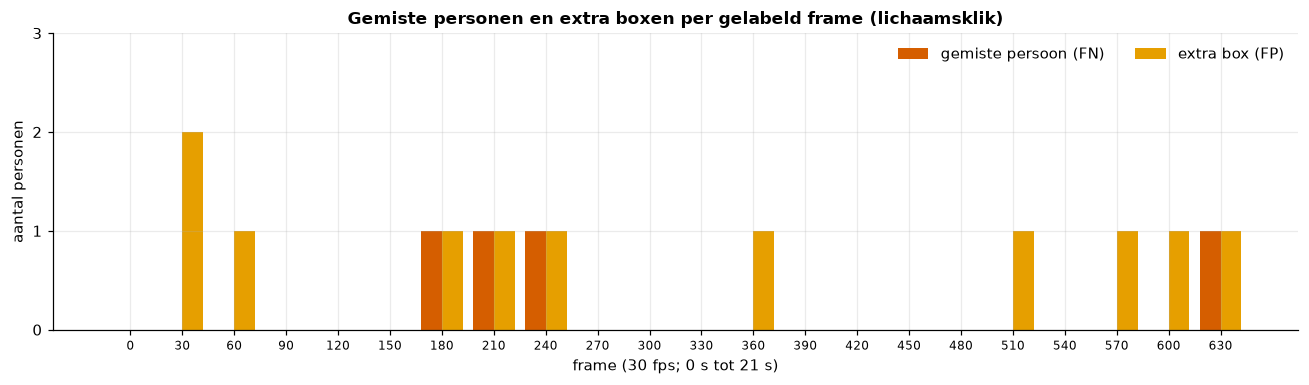

,tijd (s),personen gelabeld,FN,FP,rolfout,bal,balbezit systeem
frame,,,,,,,
30,1.0,24,0,2,0,valse bal,A
60,2.0,25,0,1,0,goed,A
180,6.0,24,1,1,0,goed,A
210,7.0,24,1,1,0,goed,A
240,8.0,24,1,1,0,valse bal,A
360,12.0,22,0,1,0,gemist,-
510,17.0,21,0,1,0,goed,A
540,18.0,22,0,0,1,verkeerde plek,A
570,19.0,22,0,1,1,goed,B


In [12]:
rows = []
for i in sorted(GT_BODY):
    n_gt = len(GT_BODY[i]["persons"])
    fn_n = int((body_fn.frame == i).sum()) if len(body_fn) else 0
    fp_n = int((body_fp.frame == i).sum()) if len(body_fp) else 0
    rows.append({"frame": i, "tijd (s)": round(i / result.fps, 1), "personen gelabeld": n_gt, "FN": fn_n, "FP": fp_n,
                 "rolfout": int(((body_pairs.frame == i) & (body_pairs.gt_role != body_pairs.pred_role)).sum()),
                 "bal": ball_tab[(ball_tab.sessie == "lichaam") & (ball_tab.frame == i)].uitkomst.iloc[0],
                 "balbezit systeem": preds_poss[i]})
per_frame_body = pd.DataFrame(rows)
per_frame_body.to_csv(OUT / "per_frame_lichaam.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(per_frame_body))
ax.bar(x - 0.2, per_frame_body.FN, 0.4, color=BAD, label="gemiste persoon (FN)")
ax.bar(x + 0.2, per_frame_body.FP, 0.4, color=COL["B"], label="extra box (FP)")
ax.set_xticks(x); ax.set_xticklabels(per_frame_body.frame, rotation=0, fontsize=8)
ax.set_xlabel("frame (30 fps; 0 s tot 21 s)"); ax.set_ylabel("aantal personen"); ax.set_yticks(range(0, int(max(per_frame_body.FN.max(), per_frame_body.FP.max())) + 2))
ax.set_title("Gemiste personen en extra boxen per gelabeld frame (lichaamsklik)"); ax.legend(ncol=2)
plt.tight_layout(); plt.show()
display(per_frame_body[(per_frame_body.FN > 0) | (per_frame_body.FP > 0) | (per_frame_body.rolfout > 0)].set_index("frame"))

**Wat we zien.** Er is geen frame waarin het systeem de weg kwijtraakt: per frame gaat het om hooguit 2 extra boxen of 1 gemiste persoon. De afwijkingen zitten verspreid over de clip en niet in een bepaald moment (zoals een camerazoom of een corner). Welke personen het precies betreft staat in sectie 5.

### Positiefout als functie van de plaats op het veld

De positiefout is hier de afstand tussen de voetklik en het systeem. Eerst waar op het veld de fouten zitten (pijltjes van klik naar systeem, 3x vergroot omdat ze anders onzichtbaar zijn), daarna de fout tegen de afstand tot de camera. Een pixel is op de verre zijlijn ongeveer 3 keer zoveel meter als vlak voor de camera.

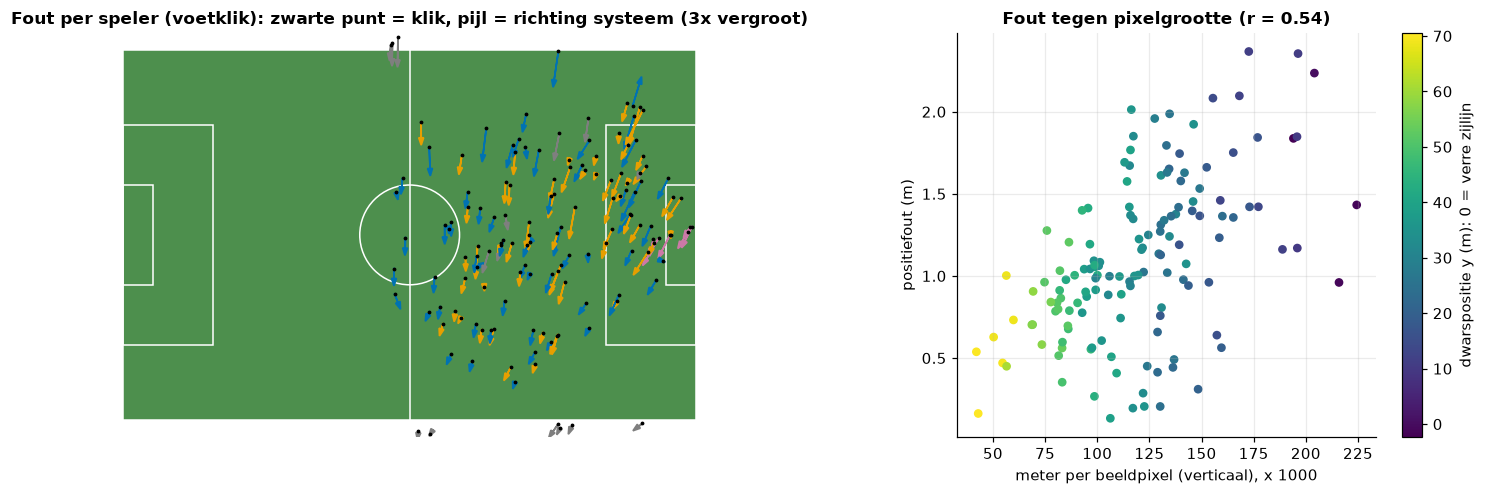

1 pixel = 4.2 cm (dichtbij) tot 22.4 cm (ver weg) in verticale richting


In [13]:
def draw_pitch(ax, color="white", lw=1.0):
    L, W = 105, 68
    ax.add_patch(plt.Rectangle((0, 0), L, W, fc="#4d8f4d", ec=color, lw=lw, zorder=0))
    ax.plot([L / 2, L / 2], [0, W], color=color, lw=lw)
    ax.add_patch(plt.Circle((L / 2, W / 2), 9.15, fill=False, ec=color, lw=lw))
    for x0, d in ((0, 1), (L, -1)):
        ax.add_patch(plt.Rectangle((x0 if d > 0 else L - 16.5, W / 2 - 20.16), 16.5, 40.32, fill=False, ec=color, lw=lw))
        ax.add_patch(plt.Rectangle((x0 if d > 0 else L - 5.5, W / 2 - 9.16), 5.5, 18.32, fill=False, ec=color, lw=lw))
    ax.set_xlim(-3, L + 3); ax.set_ylim(W + 3, -3); ax.set_aspect("equal"); ax.axis("off")   # y=0 = verre zijlijn (boven)

hs = result.homographies
def metres_per_pixel(frame, px):
    # size of one image pixel on the pitch (vertical = image y direction) at a click position
    p = np.array([px, [px[0], px[1] + 1], [px[0] + 1, px[1]]], float)
    m = hs.image_to_pitch(p, frame)
    return float(np.hypot(*(m[1] - m[0]))), float(np.hypot(*(m[2] - m[0])))

feet_pairs["mpp_vert"] = [metres_per_pixel(f, px)[0] for f, px in zip(feet_pairs.frame, feet_pairs.gt_px)]
feet_pairs["gx"] = [m[0] for m in feet_pairs.gt_m]; feet_pairs["gy"] = [m[1] for m in feet_pairs.gt_m]

fig = plt.figure(figsize=(15, 4.6))
ax0 = fig.add_subplot(1, 3, (1, 2))
draw_pitch(ax0)
for _, r in feet_pairs.iterrows():
    dx, dy = (r.pred_m[0] - r.gx) * 3, (r.pred_m[1] - r.gy) * 3
    ax0.arrow(r.gx, r.gy, dx, dy, head_width=0.9, length_includes_head=True, color=COL[r.gt_role] if r.gt_role != "B" else "#E69F00", lw=1.1, zorder=3)
    ax0.plot(r.gx, r.gy, ".", color="black", ms=3, zorder=4)
ax0.set_title("Fout per speler (voetklik): zwarte punt = klik, pijl = richting systeem (3x vergroot)")
ax1 = fig.add_subplot(1, 3, 3)
sc = ax1.scatter(feet_pairs.mpp_vert * 1000, feet_pairs.dist, c=feet_pairs.gy, cmap="viridis", s=22)
cb = plt.colorbar(sc, ax=ax1); cb.set_label("dwarspositie y (m): 0 = verre zijlijn")
ax1.set_xlabel("meter per beeldpixel (verticaal), x 1000"); ax1.set_ylabel("positiefout (m)")
r_s = np.corrcoef(feet_pairs.mpp_vert, feet_pairs.dist)[0, 1]
ax1.set_title(f"Fout tegen pixelgrootte (r = {r_s:.2f})")
plt.tight_layout(); plt.show()
print(f"1 pixel = {feet_pairs.mpp_vert.min() * 100:.1f} cm (dichtbij) tot {feet_pairs.mpp_vert.max() * 100:.1f} cm (ver weg) in verticale richting")

In [14]:
# fout per zone van het veld (aantal spelers is klein; groepen zijn grof)
feet_pairs["zone_x"] = pd.cut(feet_pairs.gx, [0, 35, 70, 105], labels=["x < 35 m", "35-70 m", "x > 70 m"])
feet_pairs["zone_y"] = pd.cut(feet_pairs.gy, [0, 23, 46, 68], labels=["verre kant (y < 23)", "midden", "dichtbije kant (y > 46)"])
for col in ("zone_x", "zone_y"):
    display(feet_pairs.groupby(col, observed=True).dist.agg(n="size", gemiddeld="mean", mediaan="median", max="max").round(2))

,n,gemiddeld,mediaan,max
zone_x,,,,
35-70 m,44,0.96,0.97,2.08
x > 70 m,96,1.15,1.17,2.37


,n,gemiddeld,mediaan,max
zone_y,,,,
verre kant (y < 23),32,1.35,1.38,2.37
midden,75,1.11,1.07,2.01
dichtbije kant (y > 46),24,0.77,0.79,1.28


**Wat we zien.** Een beeldpixel beslaat aan de verre zijlijn ongeveer 22 cm en vlak bij de camera 4 cm (factor 5). De fout is dan ook het grootst aan de **verre kant** van het veld (boven in de minimap): gemiddeld 1,35 m voor spelers op minder dan 23 m van de verre zijlijn tegen 0,77 m aan de dichtbije kant, en de fout stijgt met de pixelgrootte (r = 0,54). Eén pixel meer of minder in de box of in de klik telt daar dus zwaarder. De voetsessie heeft geen spelers op de eigen helft (x < 35 m) omdat PSG de hele clip aan de rechterkant aanvalt. Met 6 frames en 140 punten blijft het een indicatie, geen bewijs.

In de pijltjesfiguur valt iets op wat het gemiddelde verbergt: **bijna alle pijlen wijzen dezelfde kant op** (naar beneden = naar de dichtbije zijlijn). De fout is dus voor een groot deel **systematisch** en niet willekeurig. We meten dat: het gemiddelde van de getekende fout (systeem min klik) per richting, en de fout die overblijft als je dat gemiddelde eraf trekt.

In [15]:
dx = np.array([p[0] - g[0] for p, g in zip(feet_pairs.pred_m, feet_pairs.gt_m)])
dy = np.array([p[1] - g[1] for p, g in zip(feet_pairs.pred_m, feet_pairs.gt_m)])
resid = np.hypot(dx - dx.mean(), dy - dy.mean())
# the same offset in pixels: bottom edge of the box minus the clicked feet position
dpx = np.array([bx[3] - g[1] for bx, g in zip(feet_pairs.box, feet_pairs.gt_px)])
print(f"Systematische verschuiving (systeem min klik): x {dx.mean():+.2f} m, y {dy.mean():+.2f} m (y positief = naar de dichtbije zijlijn)")
print(f"Spreiding rond die verschuiving (standaardafwijking): x {dx.std():.2f} m, y {dy.std():.2f} m")
print(f"Fout in meters: gemiddeld {feet_pairs.dist.mean():.2f} m; na aftrek van de gemiddelde verschuiving: {resid.mean():.2f} m (mediaan {np.median(resid):.2f} m)")
print(f"In pixels: de onderrand van de box ligt gemiddeld {dpx.mean():.1f} px onder de voetklik (mediaan {np.median(dpx):.1f} px)")
print(f"Aandeel spelers waarvan het systeem verder van de camera af ligt dan de klik: {(dy < 0).mean():.0%}")

Systematische verschuiving (systeem min klik): x -0.28 m, y +1.00 m (y positief = naar de dichtbije zijlijn)
Spreiding rond die verschuiving (standaardafwijking): x 0.27 m, y 0.53 m
Fout in meters: gemiddeld 1.09 m; na aftrek van de gemiddelde verschuiving: 0.48 m (mediaan 0.41 m)
In pixels: de onderrand van de box ligt gemiddeld 9.1 px onder de voetklik (mediaan 9.5 px)
Aandeel spelers waarvan het systeem verder van de camera af ligt dan de klik: 1%


**Wat we zien.** Het systeem plaatst de voeten gemiddeld 1,00 m dichter bij de camera dan de labelaar klikte (en 0,28 m meer naar links), en bijna alle spelers (99 %) liggen aan die kant. De onderrand van de box ligt gemiddeld 9 pixels onder de voetklik. Trekken we de gemiddelde verschuiving af, dan blijft een fout van 0,48 m over (mediaan 0,41 m): iets meer dan de helft van de 1,09 m is dus **systematisch**. De reden is voor een deel een **definitiekwestie**: het systeem gebruikt de onderrand van de box als voet, en de box sluit de laars en de schaduw in, terwijl een klik op de voetpositie zelf valt. Welke van de twee de "juiste" voet is, is niet scherp gedefinieerd; we kunnen ook niet uitsluiten dat de labelaar gemiddeld iets hoger klikte dan de grond. Voor een minimap die spelers tot op ongeveer een meter nauwkeurig toont is dit geen probleem. Voor snelheden en afgelegde afstanden is een constante verschuiving zelfs onschadelijk, want die valt weg als je het verschil tussen twee posities neemt (zie notebook 05).

## 4. Varianten op dezelfde ground truth

Welke instellingen van de pijplijn hebben effect op het eindresultaat? We draaien varianten met dezelfde ground truth. Dat kan alleen voor combinaties waarvan de YOLO-detecties in `streamlit/cache/` staan; nieuwe combinaties zouden YOLO opnieuw op de hele clip starten en dat doen we op een laptop zonder GPU niet.

| Variant | Wat verandert er? |
|---|---|
| **finaal** (`imgsz` 1280, baldrempel 0,2) | de gekozen standaardinstelling |
| `imgsz` 960 | YOLO ziet het beeld kleiner (960 is de trainingsgrootte); de bal is dan maar enkele pixels |
| baldrempel 0,1 / 0,3 | minimale zekerheid van een baldetectie, toegepast na YOLO |
| IoU 0,5 en NMS uit (960) | hoe overlappende boxen worden samengevoegd (NMS = non-maximum suppression) |
| herdetectie (`ball_refine`) | frames zonder bal opnieuw doorzoeken in een uitsnede rond de verwachte plaats |
| fine-tuned bal-model (`best_ball_ft.pt`) | het bal-fine-tune-experiment, dat uiteindelijk **niet** werd gebruikt |

**Over de herdetectie.** `ball_refine=True` start YOLO op elke uitsnede die nog niet in de cache zit (ongeveer 0,3 s per uitsnede op CPU). We controleren eerst welke uitsnedes ontbreken:

In [16]:
FT_WEIGHTS = MODELS_DIR / "experimenten" / "best_ball_ft.pt"

def refine_check(**kw):
    r0 = pipe.run(**kw)
    windows = pipe.refine_windows(r0)
    return len(windows), len(ball_refine.missing_crops(r0.video, r0.weights, windows))

check = pd.DataFrame([{"instelling": f"imgsz {kw.get('imgsz', 1280)}, baldrempel {kw.get('ball_conf', 0.2)}",
                       "uitsneden nodig": refine_check(**kw)[0], "ontbreken in de cache": refine_check(**kw)[1]}
                      for kw in (dict(), dict(imgsz=960), dict(imgsz=960, ball_conf=0.1))])
display(check)

,instelling,uitsneden nodig,ontbreken in de cache
0,"imgsz 1280, baldrempel 0.2",161,156
1,"imgsz 960, baldrempel 0.2",227,105
2,"imgsz 960, baldrempel 0.1",192,0


Alleen bij `imgsz` 960 met baldrempel 0,1 zit alles in de cache (0 ontbrekende uitsnedes). Herdetectie vergelijken we daarom op die instelling, tegenover dezelfde instelling **zonder** herdetectie. Voor 1280 met herdetectie ontbreken er 156 uitsnedes; die variant draaien we niet.

In [17]:
def score(r):
    # one row of numbers per pipeline result, on both ground-truth sets
    p, bl, q = to_preds(r)
    eb = evaluate(GT_BODY, p, bl, q, anchor="body")
    ef = evaluate(GT_FEET, p, bl, q, anchor="feet")
    n_ball = eb["ball"]["frames_with_ball"] + ef["ball"]["frames_with_ball"]
    found = sum(round(e["ball"]["frames_with_ball"] * e["ball"]["detection_rate"]) for e in (eb, ef))
    within = sum(round(e["ball"]["frames_with_ball"] * e["ball"]["detection_rate"] * e["ball"]["within_3m"]) for e in (eb, ef))
    n_none = eb["ball"]["frames_without_ball"] + ef["ball"]["frames_without_ball"]
    false = sum(round(e["ball"]["frames_without_ball"] * e["ball"]["false_ball_rate"]) for e in (eb, ef))
    poss_ok = round(eb["possession"]["accuracy"] * eb["possession"]["n"]) + round(ef["possession"]["accuracy"] * ef["possession"]["n"])
    return {"spelers F1": eb["players"]["f1"], "precisie": eb["players"]["precision"], "recall": eb["players"]["recall"],
            "rol juist": eb["teams"]["role_accuracy"], "rol juist (voet)": ef["teams"]["role_accuracy"],
            "positiefout gem. (m)": ef["players"]["position_error_m"]["mean"],
            "bal gevonden": found, "bal binnen 3 m": within, f"van": n_ball, "valse bal": false, "van (zonder bal)": n_none,
            "balbezit juist (van 28)": poss_ok, "balframes in clip": len(r.ball)}

VARIANTS = {
    "finaal: 1280, drempel 0,2": dict(),
    "1280, drempel 0,1": dict(ball_conf=0.1),
    "1280, drempel 0,3": dict(ball_conf=0.3),
    "960, drempel 0,2": dict(imgsz=960),
    "960, drempel 0,1": dict(imgsz=960, ball_conf=0.1),
    "960, drempel 0,1 + herdetectie": dict(imgsz=960, ball_conf=0.1, ball_refine=True),
    "960, IoU 0,5": dict(imgsz=960, iou=0.5),
    "960, NMS uit": dict(imgsz=960, nms=False),
    "fine-tuned bal-model, 1280": dict(weights=FT_WEIGHTS),
    "fine-tuned bal-model, 960": dict(weights=FT_WEIGHTS, imgsz=960),
}
rows = {}
for name, kw in VARIANTS.items():
    if kw.get("ball_refine"):                       # safety: only run when no crop is missing
        n_win, n_missing = refine_check(imgsz=kw["imgsz"], ball_conf=kw["ball_conf"])
        if n_missing:                              # never start YOLO on crops here: skip the variant
            print(f"overgeslagen: {name} ({n_missing} uitsneden ontbreken in de cache)")
            continue
    rows[name] = score(pipe.run(**kw))
variants = pd.DataFrame(rows).T
variants["balframes in clip"] = variants["balframes in clip"].astype(int)
variants.to_csv(OUT / "varianten_vergelijking.csv")
show = variants.copy()
for c in ("spelers F1", "precisie", "recall", "rol juist", "rol juist (voet)"):
    show[c] = show[c].map("{:.3f}".format)
show["positiefout gem. (m)"] = show["positiefout gem. (m)"].map("{:.2f}".format)
show["bal gevonden"] = show["bal gevonden"].astype(int).astype(str) + " / " + show["van"].astype(int).astype(str)
show["bal binnen 3 m"] = show["bal binnen 3 m"].astype(int).astype(str) + " / " + show["van"].astype(int).astype(str)
show["valse bal"] = show["valse bal"].astype(int).astype(str) + " / " + show["van (zonder bal)"].astype(int).astype(str)
show["balbezit juist (van 28)"] = show["balbezit juist (van 28)"].astype(int)
display(show.drop(columns=["van", "van (zonder bal)"]))

,spelers F1,precisie,recall,rol juist,rol juist (voet),positiefout gem. (m),bal gevonden,bal binnen 3 m,valse bal,balbezit juist (van 28),balframes in clip
"finaal: 1280, drempel 0,2",0.986,0.979,0.992,0.992,0.993,1.09,19 / 21,18 / 21,5 / 7,21,499
"1280, drempel 0,1",0.986,0.979,0.992,0.992,0.993,1.09,19 / 21,18 / 21,5 / 7,21,530
"1280, drempel 0,3",0.986,0.979,0.992,0.992,0.993,1.09,17 / 21,16 / 21,1 / 7,21,422
"960, drempel 0,2",0.986,0.977,0.994,0.990,0.986,1.12,15 / 21,14 / 21,2 / 7,20,433
"960, drempel 0,1",0.986,0.977,0.994,0.990,0.986,1.12,16 / 21,15 / 21,5 / 7,21,468
"960, drempel 0,1 + herdetectie",0.986,0.977,0.994,0.990,0.986,1.12,17 / 21,16 / 21,5 / 7,22,469
"960, IoU 0,5",0.988,0.983,0.994,0.977,0.971,1.12,15 / 21,14 / 21,2 / 7,20,433
"960, NMS uit",0.977,0.961,0.994,0.971,0.979,1.13,13 / 21,13 / 21,0 / 7,18,355
"fine-tuned bal-model, 1280",0.984,0.979,0.988,0.992,0.993,0.97,19 / 21,19 / 21,4 / 7,19,495
"fine-tuned bal-model, 960",0.984,0.979,0.988,0.998,1.000,0.98,16 / 21,15 / 21,1 / 7,17,433


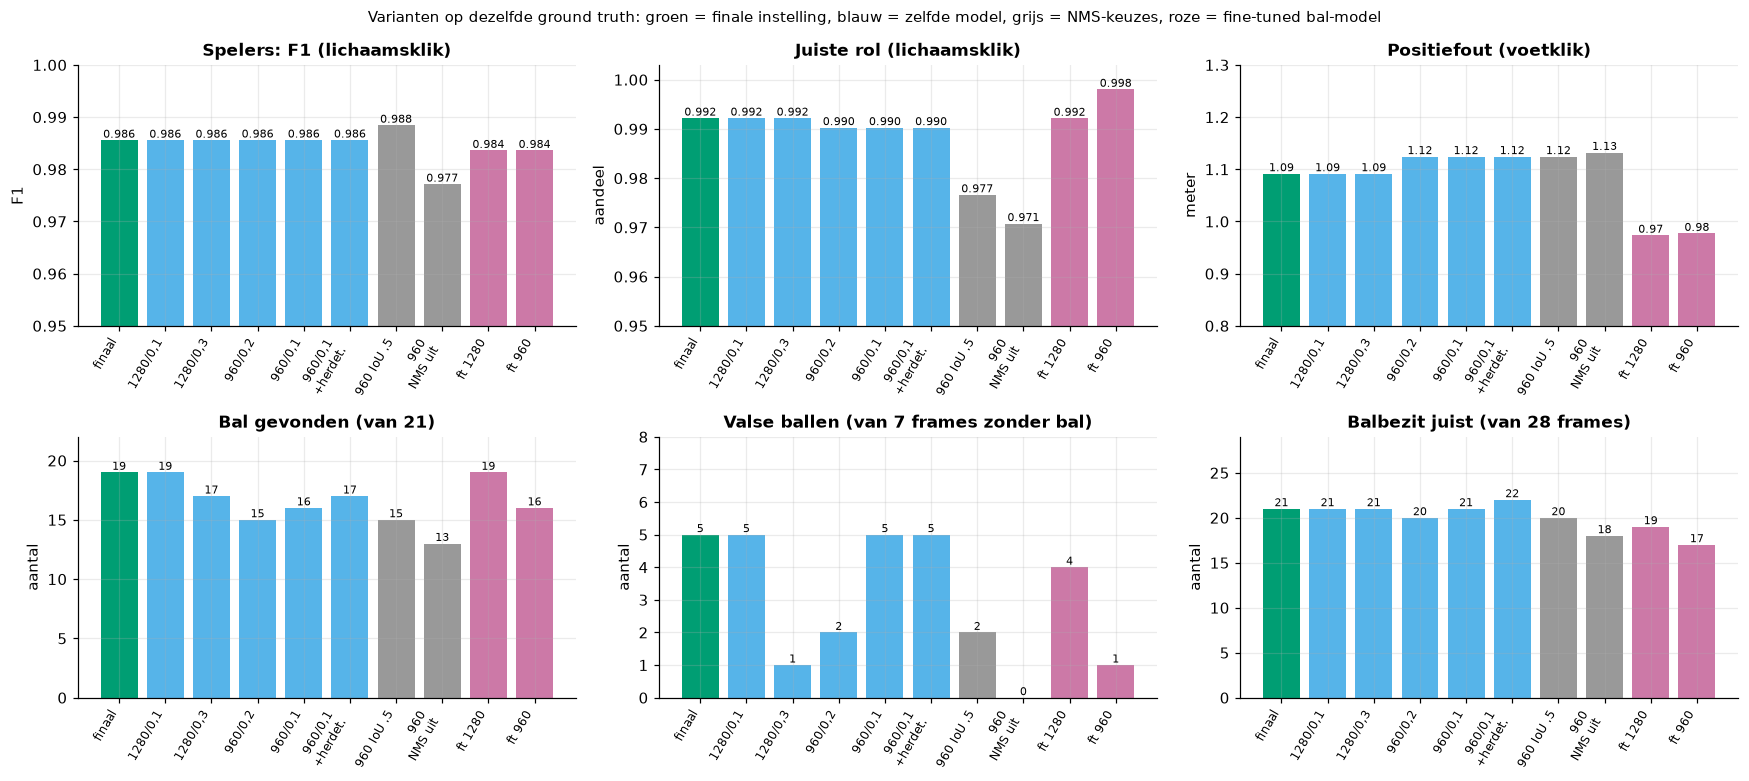

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(16, 7.2))
names = list(variants.index)
_short = ["finaal", "1280/0,1", "1280/0,3", "960/0,2", "960/0,1", "960/0,1\n+herdet.", "960 IoU .5", "960\nNMS uit", "ft 1280", "ft 960"]
_colors = [GOOD] + [NEUTRAL] * 5 + ["#999999"] * 2 + ["#CC79A7"] * 2
# a variant can be skipped (e.g. no crop cache for the active model): label and colour follow the variant name
short = [dict(zip(VARIANTS, _short))[n] for n in names]
colors = [dict(zip(VARIANTS, _colors))[n] for n in names]
def panel(a, col, title, ylabel, ylim=None, scale=1.0, fmt_="{:.3f}"):
    v = variants[col].astype(float) * scale
    a.bar(range(len(v)), v, color=colors)
    a.set_xticks(range(len(v))); a.set_xticklabels(short, rotation=60, fontsize=8, ha="right"); a.set_title(title); a.set_ylabel(ylabel)
    if ylim: a.set_ylim(*ylim)
    for i, x in enumerate(v): a.text(i, x, fmt_.format(x), ha="center", va="bottom", fontsize=7)
panel(ax[0, 0], "spelers F1", "Spelers: F1 (lichaamsklik)", "F1", (0.95, 1.0))
panel(ax[0, 1], "rol juist", "Juiste rol (lichaamsklik)", "aandeel", (0.95, 1.003))
panel(ax[0, 2], "positiefout gem. (m)", "Positiefout (voetklik)", "meter", (0.8, 1.3), fmt_="{:.2f}")
panel(ax[1, 0], "bal gevonden", "Bal gevonden (van 21)", "aantal", (0, 22), fmt_="{:.0f}")
panel(ax[1, 1], "valse bal", "Valse ballen (van 7 frames zonder bal)", "aantal", (0, 8), fmt_="{:.0f}")
panel(ax[1, 2], "balbezit juist (van 28)", "Balbezit juist (van 28 frames)", "aantal", (0, 29), fmt_="{:.0f}")
plt.suptitle("Varianten op dezelfde ground truth: groen = finale instelling, blauw = zelfde model, grijs = NMS-keuzes, roze = fine-tuned bal-model", fontsize=10)
plt.tight_layout(); plt.show()

**Wat we zien.**

- **Spelers zijn bijna ongevoelig voor de instellingen.** F1 ligt in alle varianten tussen 0,977 en 0,988, de juiste rol tussen 0,97 en 1,00 en de positiefout rond 1 m. Wat de bal betreft: de spelers-cijfers komen uit andere stappen en blijven stabiel. Alleen **NMS uit** is merkbaar slechter (meer extra boxen, lagere precisie), en IoU 0,5 geeft een iets slechtere rolscore.
- **De bal is gevoelig.** `imgsz` 1280 vindt 19 van 21 ballen, 960 vindt er 15 (drempel 0,2) of 16 (drempel 0,1). De bal is maar enkele pixels groot en profiteert van het grotere beeld. Dat is de reden dat 1280 de standaard werd.
- **Baldrempel**: een lagere drempel levert meer balframes, maar geen extra juiste ballen op 1280 (0,1 en 0,2 geven dezelfde 19/21 en 5/7). Een drempel van 0,3 haalt 4 valse ballen weg (nog 1 van 7), maar verliest 2 juiste (17/21). Dit is een afweging tussen gemiste en valse ballen.
- **Herdetectie** voegt bij 960 één bal toe (16 naar 17 van 21) en verhoogt de balbezitscore van 21 naar 22 van 28. Het haalt de valse ballen niet weg. Voor het finale model (1280) kunnen we het niet vergelijken zonder YOLO te starten.
- **Het fine-tuned bal-model** (`best_ball_ft.pt`) levert op 1280 ook 19/21 gevonden ballen en een iets lagere positiefout (0,97 m), maar scoort op balbezit slechter (19 tegenover 21 van 28) en is een **mislukt experiment**: volgens de projectgeschiedenis was de leersnelheid te hoog en was epoch 1 van 16 de beste. Het wordt niet gebruikt.

### Klopt dit met de eerder gerapporteerde cijfers?

In de projectgeschiedenis staat: spelers F1 0,99, juiste rol 99,6-100 %, positiefout 0,5-1,1 m en 19 van 21 ballen met de nieuwe standaard. We komen op: F1 0,986 (lichaam) en 0,989 (voet), rol 99,2 % en 99,3 %, positiefout 1,09 m gemiddeld (de mediaan is 1,03 m) en 19 van 21 ballen. Dat komt overeen, met twee kanttekeningen:

1. De rol is bij het finale model 99,2-99,3 %, iets onder de geciteerde 99,6-100 %. De rol van 99,6-100 % vinden we terug bij het fine-tuned bal-model (99,8 % en 100 %): dat is vermoedelijk waar de bandbreedte vandaan komt. We kunnen dat niet uit de geschiedenis zelf afleiden.
2. De ondergrens van 0,5 m voor de positiefout herkennen we niet als gemiddelde spelersfout (het minimum over alle varianten is 0,97 m). We vinden 0,48 m op twee andere plaatsen: de gemiddelde **balfout** op de voetset en de spelersfout nadat we de systematische verschuiving van sectie 3 hebben afgetrokken. We kunnen uit de geschiedenis niet afleiden welke van de twee bedoeld is.

### De baldrempel in detail

De drempel bepaalt de afweging tussen gemiste ballen en valse ballen. Omdat een drempelwijziging na YOLO plaatsvindt, kunnen we hem voor de cache-varianten vrij laten lopen.

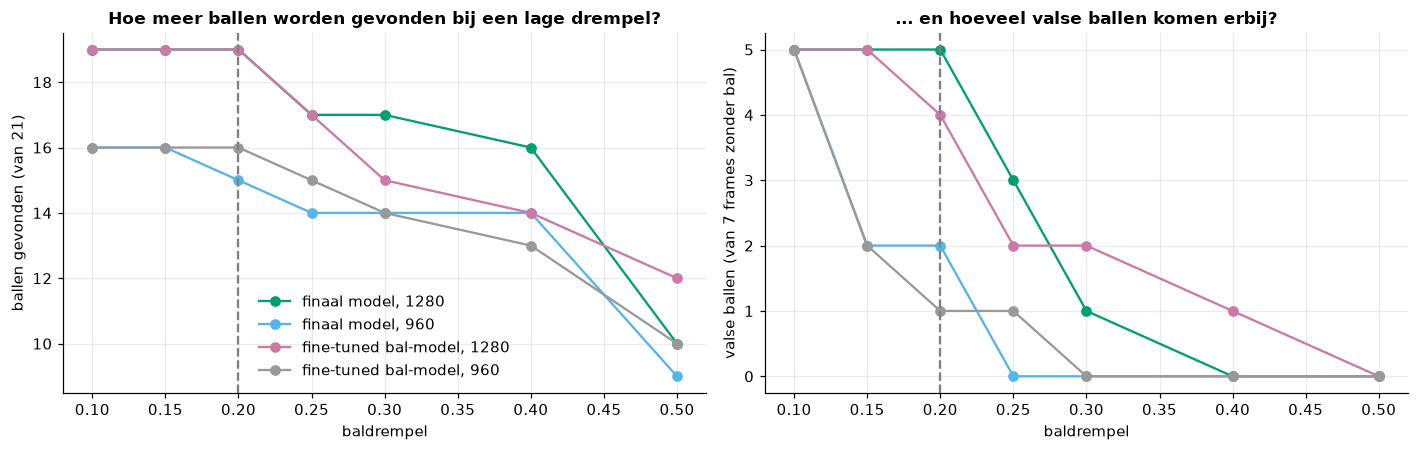

model,"gevonden: finaal model, 1280","gevonden: finaal model, 960","gevonden: fine-tuned bal-model, 1280","gevonden: fine-tuned bal-model, 960","vals: finaal model, 1280","vals: finaal model, 960","vals: fine-tuned bal-model, 1280","vals: fine-tuned bal-model, 960"
drempel,,,,,,,,
0.10,19,16,19,16,5,5,5,5
0.15,19,16,19,16,5,2,5,2
0.20,19,15,19,16,5,2,4,1
0.25,17,14,17,15,3,0,2,1
0.30,17,14,15,14,1,0,2,0
0.40,16,14,14,13,0,0,1,0
0.50,10,9,12,10,0,0,0,0


In [19]:
sweep = []
for label, kw0 in (("finaal model, 1280", dict()), ("finaal model, 960", dict(imgsz=960)),
                   ("fine-tuned bal-model, 1280", dict(weights=FT_WEIGHTS)), ("fine-tuned bal-model, 960", dict(weights=FT_WEIGHTS, imgsz=960))):
    for t in (0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5):
        s = score(pipe.run(**kw0, ball_conf=t))
        sweep.append({"model": label, "drempel": t, "gevonden": s["bal gevonden"], "binnen 3 m": s["bal binnen 3 m"], "valse bal": s["valse bal"], "balframes": s["balframes in clip"]})
sweep = pd.DataFrame(sweep)
sweep.to_csv(OUT / "baldrempel_sweep.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cols = {"finaal model, 1280": GOOD, "finaal model, 960": NEUTRAL, "fine-tuned bal-model, 1280": "#CC79A7", "fine-tuned bal-model, 960": "#999999"}
for label, g in sweep.groupby("model", sort=False):
    ax[0].plot(g.drempel, g["gevonden"], "o-", color=cols[label], label=label)
    ax[1].plot(g.drempel, g["valse bal"], "o-", color=cols[label], label=label)
ax[0].axvline(0.2, color="grey", ls="--"); ax[1].axvline(0.2, color="grey", ls="--")
ax[0].set_xlabel("baldrempel"); ax[0].set_ylabel("ballen gevonden (van 21)"); ax[0].set_title("Hoe meer ballen worden gevonden bij een lage drempel?"); ax[0].legend()
ax[1].set_xlabel("baldrempel"); ax[1].set_ylabel("valse ballen (van 7 frames zonder bal)"); ax[1].set_title("... en hoeveel valse ballen komen erbij?")
plt.tight_layout(); plt.show()
display(sweep.pivot(index="drempel", columns="model", values="gevonden").assign(**{}).astype(int).add_prefix("gevonden: ").join(
        sweep.pivot(index="drempel", columns="model", values="valse bal").astype(int).add_prefix("vals: ")))

**Wat we zien.** Op 1280 blijven 19 ballen gevonden tot en met een drempel van 0,2. Bij 0,25 zijn het er 17 en bij 0,5 nog maar 10, terwijl de valse ballen pas bij hogere drempels verdwijnen (5, 3 bij 0,25, 1 bij 0,3, 0 vanaf 0,4). De gekozen 0,2 is dus de **hoogste drempel zonder verlies aan gevonden ballen**; hoger levert minder valse ballen maar ook gemiste ballen op. Op 960 worden bij elke drempel minder ballen gevonden dan op 1280. De 7 frames zonder bal zijn erg weinig: één frame meer of minder verandert het percentage met 14 punten.

Een keuze op basis van de ground truth die we ook voor de evaluatie gebruiken is bovendien **niet onafhankelijk**: de drempel is gekozen op diezelfde 21 ballen waarop we hem nu beoordelen. De 19/21 is dus een optimistische schatting (zie Beperkingen).

## 5. Foutenanalyse: de fouten één voor één

Cijfers vertellen *hoeveel* er misgaat, niet *waarom*. Daarom bekijken we elke fout afzonderlijk: eerst de bal (gemist, verkeerde plek, valse bal), dan de spelers (gemiste personen, extra boxen, verkeerde rollen) en tenslotte het balbezit. Voor elke fout kijken we naar wat YOLO zelf zag: de cache bevat alle detecties vanaf zekerheid 0,05, dus we zien ook wat de pijplijn heeft weggegooid.

### 5.1 De bal in de tijd

Eerst het grote plaatje: per frame de status van de bal, met daarbovenop de 28 gelabelde frames.

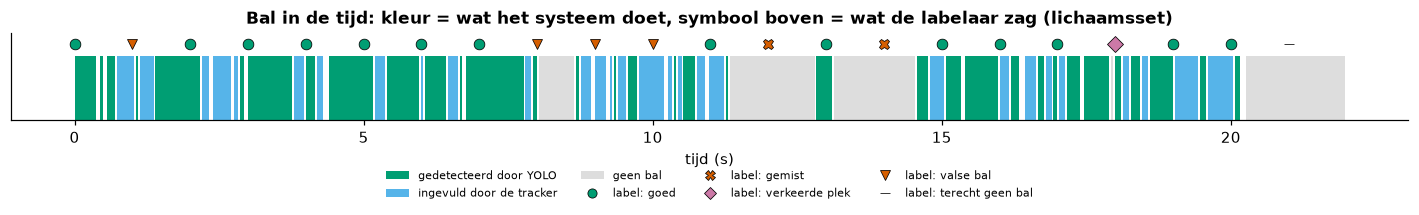

{'geen': 161, 'ingevuld': 191, 'gedetecteerd': 308} frames van 660


In [20]:
dets = {f["frame"]: f["detections"] for f in detect(str(VIDEO), str(DEFAULT_WEIGHTS), pipe.DEFAULT_IMGSZ, 0.7, 0, 659, 1)}   # uit de cache

state = np.array([{"detected": 2, "refined": 2, "interpolated": 1}.get(result.ball[i]["state"], 0) if i in result.ball else 0 for i in result.ids])
fig, ax = plt.subplots(figsize=(13, 2.6))
for val, color, name in ((2, GOOD, "gedetecteerd door YOLO"), (1, NEUTRAL, "ingevuld door de tracker"), (0, "#dddddd", "geen bal")):
    ax.fill_between(np.array(result.ids) / result.fps, 0, 1, where=(state == val), color=color, step="mid", label=name, lw=0)
marker = {"goed": ("o", GOOD), "gemist": ("X", BAD), "verkeerde plek": ("D", "#CC79A7"), "valse bal": ("v", BAD), "terecht geen bal": ("_", "black")}
for _, r in ball_tab[ball_tab.sessie == "lichaam"].iterrows():
    m, c = marker[r.uitkomst]
    ax.plot(r.frame / result.fps, 1.18, m, color=c, ms=7, mec="black", mew=0.5)
for k, (m, c) in marker.items():
    ax.plot([], [], m, color=c, mec="black", mew=0.5, label=f"label: {k}", ls="")
ax.set_ylim(0, 1.35); ax.set_yticks([]); ax.set_xlabel("tijd (s)"); ax.set_title("Bal in de tijd: kleur = wat het systeem doet, symbool boven = wat de labelaar zag (lichaamsset)")
ax.legend(ncol=4, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.45)); ax.grid(False)
plt.tight_layout(); plt.show()
print({k: int(v) for k, v in zip(("geen", "ingevuld", "gedetecteerd"), np.bincount(state, minlength=3))}, "frames van", len(state))

### 5.2 De problematische ballen: gemist, verkeerde plek en valse bal

Voor elk probleemframe tonen we een vergrote uitsnede: **groene cirkel** = waar de labelaar de bal klikte, **oranje vierkant** = waar het systeem de bal plaatst (met `D` = door YOLO gezien, `I` = ingevuld). Daaronder wat de detectiecache zei over de omgeving, en welke filter van de pijplijn een kandidaat heeft verworpen.

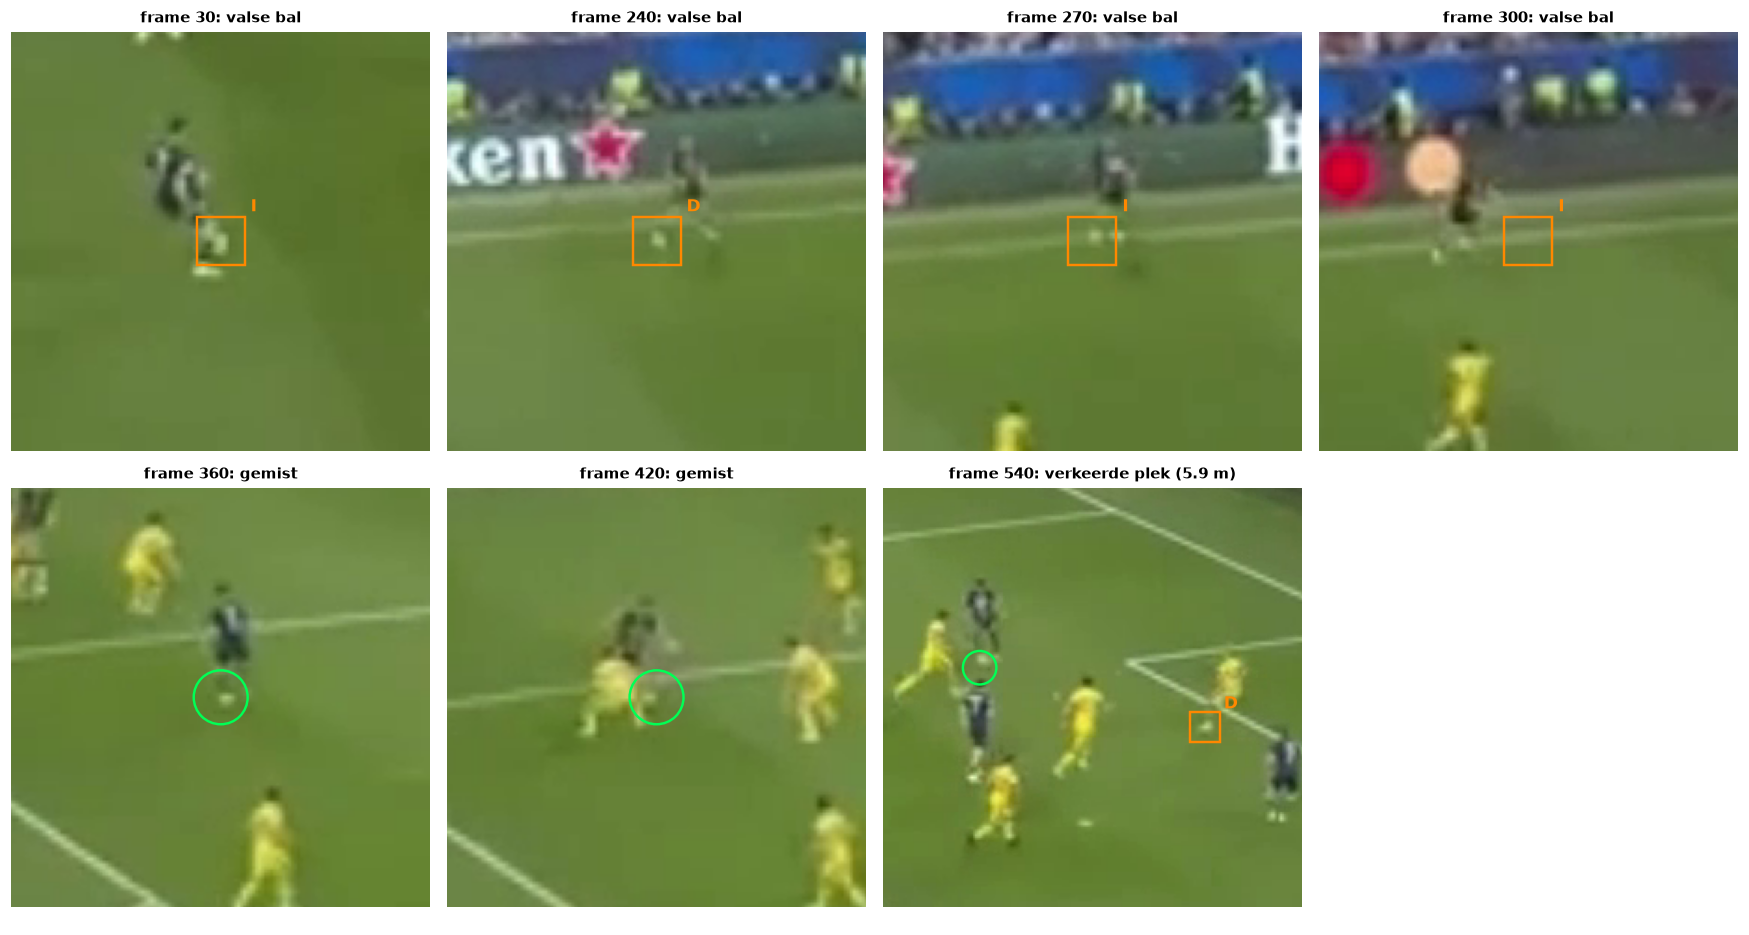

In [21]:
def reject_reason(d, idx, min_conf=0.2):
    # why does ball_candidate() drop this detection (or None when it passes)
    x1, y1, x2, y2 = d["box"]
    if d["conf"] < min_conf:
        return f"zekerheid {d['conf']:.2f} < drempel {min_conf}"
    if max(x2 - x1, y2 - y1) > MAX_BALL_SIZE:
        return "box te groot (geen bal)"
    xy = hs.image_to_pitch([((x1 + x2) / 2, (y1 + y2) / 2)], idx)[0]
    if not pipe.on_pitch(xy):
        return "buiten het veld"
    if min(np.hypot(*np.subtract(xy, s)) for s in SPOTS) <= SPOT_RADIUS:
        return "op een witte stip van het veld"
    return None

def ball_candidates_near(idx, px, radius=130):
    rows = []
    for d in dets[idx]:
        if d["name"] not in ("ball", "sports ball"):
            continue
        x1, y1, x2, y2 = d["box"]
        dist = np.hypot((x1 + x2) / 2 - px[0], (y1 + y2) / 2 - px[1])
        if dist <= radius:
            rows.append({"afstand tot klik (px)": round(dist), "zekerheid": d["conf"], "box": [round(v) for v in d["box"]],
                         "verworpen omdat": reject_reason(d, idx) or "-"})
    return pd.DataFrame(rows)

problem = ball_tab[ball_tab.uitkomst.isin(["gemist", "verkeerde plek", "valse bal"])].sort_values(["frame", "sessie"])
problem = problem.drop_duplicates("frame")          # frame 240 komt in beide sessies voor
fig, axes = plt.subplots(2, 4, figsize=(16, 8.6)); axes = axes.ravel()
for ax, (_, r) in zip(axes, problem.iterrows()):
    pb = result.ball.get(r.frame)
    pts = []
    if r.gt_px is not None: pts.append(r.gt_px)
    if pb:
        ppx = hs.pitch_to_image([(pb["x_m"], pb["y_m"])], r.frame)[0]; pts.append(ppx)
    cx, cy = np.mean(pts, axis=0); half = max(70, max(np.hypot(*(np.array(p) - [cx, cy])) for p in pts) + 50)
    img = cv2.cvtColor(read_frame(VIDEO, r.frame), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy + half, cy - half); ax.axis("off")
    if r.gt_px is not None:
        ax.add_patch(plt.Circle(r.gt_px, 9, fill=False, ec="#00ff55", lw=1.6))
    if pb:
        ax.add_patch(plt.Rectangle((ppx[0] - 8, ppx[1] - 8), 16, 16, fill=False, ec="#ff8800", lw=1.6))
        ax.text(ppx[0] + 10, ppx[1] - 10, "D" if pb["state"] == "detected" else "I", color="#ff8800", fontsize=11, weight="bold")
    ax.set_title(f"frame {r.frame}: {r.uitkomst}" + (f" ({r.fout_m:.1f} m)" if r.uitkomst == "verkeerde plek" else ""), fontsize=10)
for ax in axes[len(problem):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [22]:
# wat zag YOLO bij elk probleemframe? (alle ballen-detecties vanaf zekerheid 0,05 binnen 130 px van de klik of de plaats van het systeem)
analysis = []
for _, r in problem.iterrows():
    pb = result.ball.get(r.frame)
    anchor_px = r.gt_px if r.gt_px is not None else hs.pitch_to_image([(pb["x_m"], pb["y_m"])], r.frame)[0]
    near = ball_candidates_near(r.frame, anchor_px)
    print(f"--- frame {r.frame} ({r.uitkomst}); status systeem: {r.status}; kandidaten van YOLO nabij: {len(near)}")
    if len(near):
        display(near.sort_values("afstand tot klik (px)").head(4))
    analysis.append({"frame": r.frame, "uitkomst": r.uitkomst, "status systeem": r.status, "kandidaten nabij": len(near),
                     "hoogste zekerheid": float(near["zekerheid"].max()) if len(near) else None})
pd.DataFrame(analysis).to_csv(OUT / "bal_foutanalyse.csv", index=False)

--- frame 30 (valse bal); status systeem: interpolated; kandidaten van YOLO nabij: 1


,afstand tot klik (px),zekerheid,box,verworpen omdat
0,1,0.065,"[893, 670, 901, 682]",zekerheid 0.07 < drempel 0.2


--- frame 240 (valse bal); status systeem: detected; kandidaten van YOLO nabij: 1


,afstand tot klik (px),zekerheid,box,verworpen omdat
0,0,0.262,"[894, 222, 906, 234]",-


--- frame 270 (valse bal); status systeem: interpolated; kandidaten van YOLO nabij: 2


,afstand tot klik (px),zekerheid,box,verworpen omdat
0,1,0.076,"[876, 235, 886, 248]",zekerheid 0.08 < drempel 0.2
1,19,0.067,"[888, 244, 904, 258]",zekerheid 0.07 < drempel 0.2


--- frame 300 (valse bal); status systeem: interpolated; kandidaten van YOLO nabij: 0
--- frame 360 (gemist); status systeem: none; kandidaten van YOLO nabij: 0
--- frame 420 (gemist); status systeem: none; kandidaten van YOLO nabij: 0
--- frame 540 (verkeerde plek); status systeem: detected; kandidaten van YOLO nabij: 2


,afstand tot klik (px),zekerheid,box,verworpen omdat
1,102,0.065,"[1126, 473, 1139, 484]",zekerheid 0.07 < drempel 0.2
0,125,0.510,"[1189, 418, 1203, 433]",-


**Wat we zien, fout voor fout.**

| Frame | Wat de labelaar zag | Wat het systeem deed | Wat YOLO zag (cache, vanaf 0,05) | Oorzaak |
|---|---|---|---|---|
| 360, 420 | bal, enkele pixels groot tussen spelers | geen bal (gemist) | **geen enkele baldetectie** binnen 130 px | De bal is te klein en onscherp voor het model: een beperking van de detector, geen filter. Ook de tracker kan hier niet invullen: het gat is langer dan 15 frames |
| 540 | bal bij de voeten van een PSG-speler | bal 5,9 m ernaast | een detectie met zekerheid 0,51 op een wit vlekje bij een Inter-speler (waarschijnlijk een witte schoen of sok); de echte bal heeft geen kandidaat | Een **hoge-zekerheid valse positief**: de drempel kan deze niet weren, want de zekerheid is hoger dan die van veel echte ballen |
| 30 | "geen bal zichtbaar" | ingevulde bal | een kandidaat met zekerheid 0,065 op minder dan 2 pixels van de voorspelde plek | De tracker vult een gat tussen twee detecties. Op de uitsnede is op die plek een wit vlekje te zien; of dat de bal is kunnen wij niet met zekerheid zeggen |
| 240 | "geen bal zichtbaar" | door YOLO gedetecteerde bal (zekerheid 0,26) | die ene detectie, op de zijlijn bij een PSG-speler | Een wit vlekje op de zijlijn; kan een echte bal zijn die de labelaar niet kon onderscheiden |
| 270 | "geen bal zichtbaar" | ingevulde bal | twee zwakke kandidaten (0,08 en 0,07) vlakbij | Gat wordt opgevuld naast de zijlijn |
| 300 | "geen bal zichtbaar" | ingevulde bal | niets | Interpolatie zonder enig bewijs in het frame: de bal is waarschijnlijk uit beeld of uit het spel (zijlijn), maar de tracker houdt hem tot 15 frames vast |

Frame 240 komt in beide sessies voor (beide: "geen bal"); de 5 valse ballen van de metrics-tabel zijn dus 4 verschillende frames. De grote les: de **valse ballen** (30, 240, 270) zijn niet allemaal zeker fout. Bij 30, 240 en 270 ligt de bal op een plek waar een wit voorwerp te zien is, en een bal van enkele pixels is voor een mens evengoed moeilijk te zien. "Niet zichtbaar" in de labels betekent daarom niet "niet aanwezig". Alleen frame 300 is zonder meer een interpolatie zonder zichtbaar bewijs. De **gemiste ballen** (360, 420) en de **verkeerde bal** (540) zijn de echte fouten van het systeem.

### 5.3 De spelers

De lichaamsset heeft 11 extra boxen (FP) en 4 gemiste personen (FN); de voetset 3 FP en 0 FN. We bepalen bij elke fout de oorzaak met regels, op basis van de detectiecache en de boxen van het systeem:

- Bij een **FN** (gemiste persoon): was er een persoonsdetectie vlakbij (zo niet: YOLO zag niemand)? Lagen de voeten buiten het veld plus marge van 3 m (`PITCH_MARGIN`), dan filtert de pijplijn de detectie bewust weg. Overlapt de detectie een andere box, dan kan het duplicaatfilter haar hebben samengevoegd.
- Bij een **FP** (extra box): overlapt de box een andere box van het systeem (IoU $\geq$ 0,5, dubbele detectie van één speler)? Ligt er geen klik in de buurt (verder dan 2 boxhoogtes: een niet-gelabelde persoon)? Anders ligt de box naast een klik (overlappende spelers).

In [23]:
def box_iou(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

def fn_cause(row):
    i, px = row.frame, row.px
    best = None
    for d in dets[i]:
        if not is_person(d):
            continue
        bx = d["box"]
        dd = np.hypot(px[0] - (bx[0] + bx[2]) / 2, px[1] - (bx[1] + bx[3]) / 2) / max(bx[3] - bx[1], 1)
        if dd <= 0.6 and (best is None or dd < best[0]):
            best = (dd, d)
    if best is None:
        return "YOLO zag niemand (zekerheid >= 0,05)"
    d = best[1]; bx = d["box"]
    feet = hs.image_to_pitch([((bx[0] + bx[2]) / 2, bx[3])], i)[0]
    if not pipe.on_pitch(feet):
        return f"gezien (zekerheid {d['conf']:.2f}), maar de voeten liggen buiten veld + {PITCH_MARGIN:g} m marge (y = {feet[1]:.1f} m): bewust weggefilterd"
    if any(box_iou(bx, q["box"]) > 0.4 for q in preds_people[i]):
        return f"gezien (zekerheid {d['conf']:.2f}), maar samengevoegd met een overlappende box (duplicaatfilter)"
    return f"gezien (zekerheid {d['conf']:.2f}), maar zonder track niet in het resultaat"

def fp_cause(row, gt):
    i, bx = row.frame, row.box
    others = [q for q in preds_people[i] if tuple(q["box"]) != tuple(bx)]
    ov = max((box_iou(bx, q["box"]) for q in others), default=0)
    if ov >= 0.5:
        return f"dubbele box op dezelfde speler (IoU {ov:.2f} met een andere box)"
    h = bx[3] - bx[1]
    near = min(np.hypot(g["px"][0] - (bx[0] + bx[2]) / 2, g["px"][1] - (bx[1] + bx[3]) / 2) / h for g in gt[i]["persons"])
    if near > 2:
        return f"persoon zonder klik (dichtstbijzijnde klik {near:.0f} boxhoogtes ver): niet gelabeld"
    return f"naast een klik ({near:.1f} boxhoogte): overlappende spelers, niet te beslissen"

cases = []
for session, gt, fn_df, fp_df in (("lichaam", GT_BODY, body_fn, body_fp), ("voet", GT_FEET, feet_fn, feet_fp)):
    for _, r in fn_df.iterrows():
        cases.append({"sessie": session, "frame": r.frame, "soort": "FN", "rol": r.role, "oorzaak": fn_cause(r), "px": r.px, "box": None})
    for _, r in fp_df.iterrows():
        cases.append({"sessie": session, "frame": r.frame, "soort": "FP", "rol": r.role, "oorzaak": fp_cause(r, gt), "px": None, "box": r.box})
cases = pd.DataFrame(cases)
cases["categorie"] = cases.oorzaak.str.extract(r"^(dubbele box|persoon zonder klik|naast een klik|YOLO zag niemand|gezien[^,]*, maar (?:de voeten|samengevoegd|zonder))")[0]
cases.drop(columns=["px", "box"]).to_csv(OUT / "personen_fouten.csv", index=False)
pd.set_option("display.max_colwidth", 140)
display(cases[["sessie", "frame", "soort", "rol", "oorzaak"]])
display(cases.groupby(["sessie", "soort", "categorie"]).size().rename("aantal").to_frame())

,sessie,frame,soort,rol,oorzaak
0,lichaam,180,FN,R,"gezien (zekerheid 0.69), maar de voeten liggen buiten veld + 3 m marge (y = 71.0 m): bewust weggefilterd"
1,lichaam,210,FN,R,"gezien (zekerheid 0.63), maar de voeten liggen buiten veld + 3 m marge (y = 71.7 m): bewust weggefilterd"
2,lichaam,240,FN,R,"gezien (zekerheid 0.80), maar de voeten liggen buiten veld + 3 m marge (y = 71.0 m): bewust weggefilterd"
3,lichaam,630,FN,A,"gezien (zekerheid 0.50), maar samengevoegd met een overlappende box (duplicaatfilter)"
4,lichaam,30,FP,B,"naast een klik (0.4 boxhoogte): overlappende spelers, niet te beslissen"
5,lichaam,30,FP,A,dubbele box op dezelfde speler (IoU 0.59 met een andere box)
6,lichaam,60,FP,A,dubbele box op dezelfde speler (IoU 0.60 met een andere box)
7,lichaam,180,FP,B,"naast een klik (0.7 boxhoogte): overlappende spelers, niet te beslissen"
8,lichaam,210,FP,A,persoon zonder klik (dichtstbijzijnde klik 3 boxhoogtes ver): niet gelabeld
9,lichaam,240,FP,A,persoon zonder klik (dichtstbijzijnde klik 3 boxhoogtes ver): niet gelabeld


aantal
sessie  soort categorie                                         
lichaam FN    gezien (zekerheid 0.50), maar samengevoegd       1
              gezien (zekerheid 0.63), maar de voeten          1
              gezien (zekerheid 0.69), maar de voeten          1
              gezien (zekerheid 0.80), maar de voeten          1
        FP    dubbele box                                      4
              naast een klik                                   4
              persoon zonder klik                              3
voet    FP    dubbele box                                      1
              naast een klik                                   1
              persoon zonder klik                              1

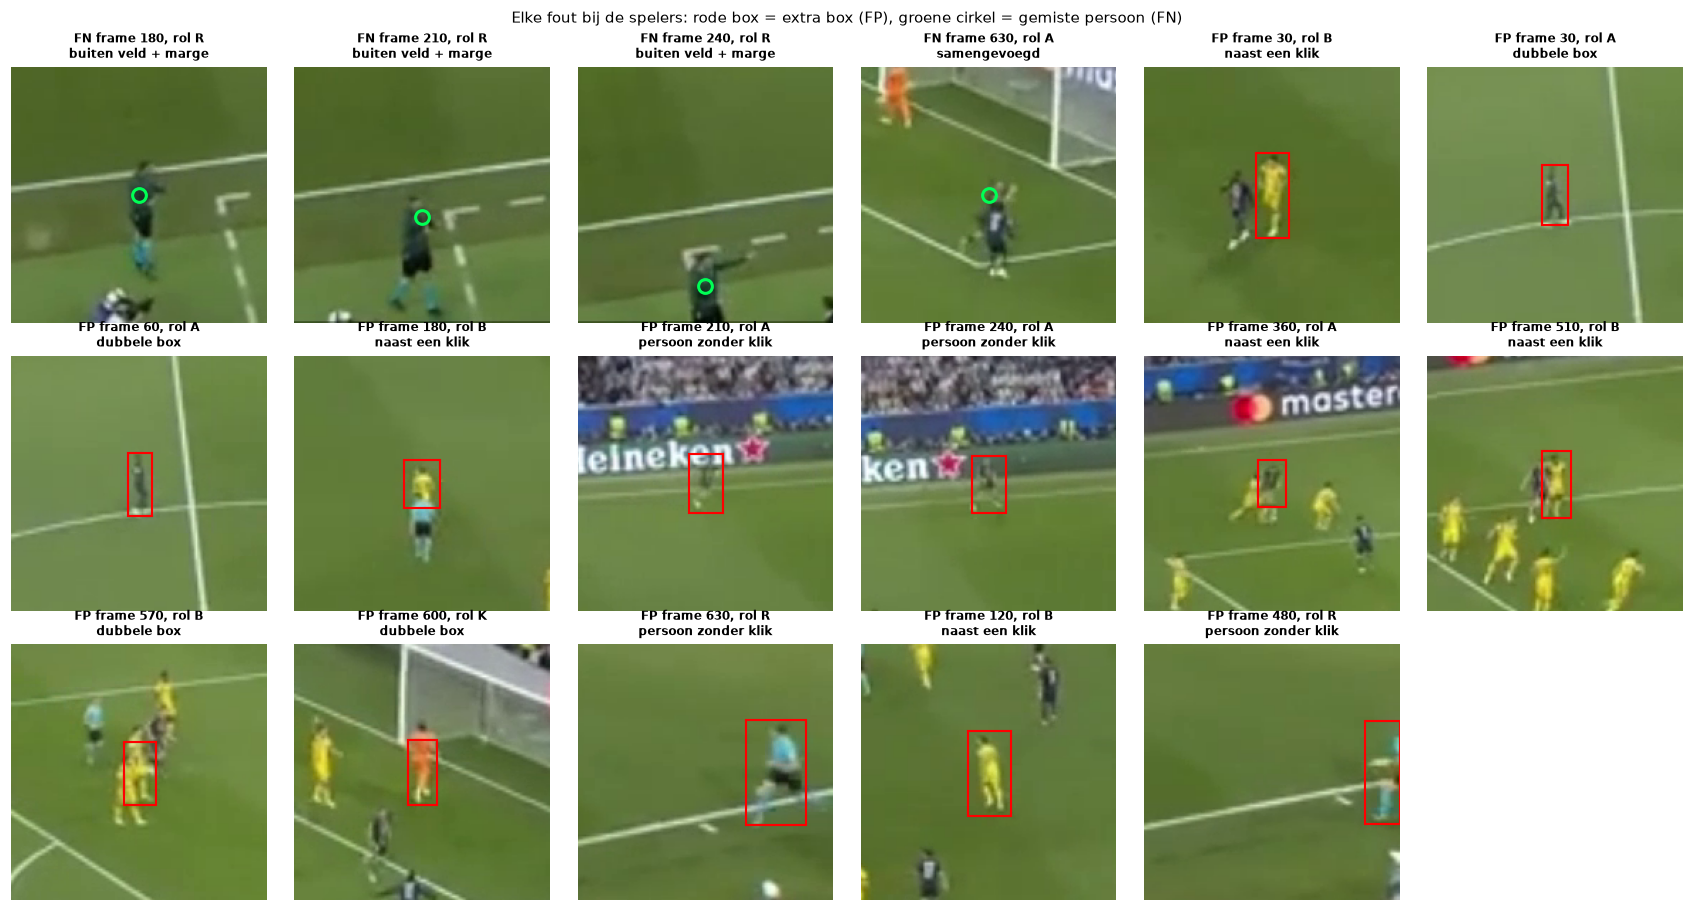

In [24]:
# de gevallen in beeld (lichaamsset + voetset; frame 600 komt in beide sessies voor)
tiles = cases.drop_duplicates(["frame", "soort", "rol"]).reset_index(drop=True)
n = len(tiles); ncol = 6; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.8 * nrow)); axes = np.atleast_2d(axes).ravel()
for ax, (_, r) in zip(axes, tiles.iterrows()):
    img = cv2.cvtColor(read_frame(VIDEO, r.frame), cv2.COLOR_BGR2RGB)
    if r.soort == "FP":
        cx, cy = (r.box[0] + r.box[2]) / 2, (r.box[1] + r.box[3]) / 2
    else:
        cx, cy = r.px
    x0, y0 = int(np.clip(cx - 90, 0, 1920 - 180)), int(np.clip(cy - 90, 0, 1080 - 180))
    ax.imshow(img[y0:y0 + 180, x0:x0 + 180], extent=(x0, x0 + 180, y0 + 180, y0)); ax.axis("off")
    if r.soort == "FP":
        ax.add_patch(plt.Rectangle((r.box[0], r.box[1]), r.box[2] - r.box[0], r.box[3] - r.box[1], fill=False, ec="red", lw=1.4))
    else:
        ax.plot(*r.px, "o", ms=9, mfc="none", mec="#00ff55", mew=2)
    short_cat = ("buiten veld + marge" if "voeten" in (r.categorie or "") else "samengevoegd" if "samengevoegd" in (r.categorie or "") else r.categorie)
    ax.set_title(f"{r.soort} frame {r.frame}, rol {r.rol}\n{short_cat}", fontsize=8)
for ax in axes[n:]:
    ax.axis("off")
plt.suptitle("Elke fout bij de spelers: rode box = extra box (FP), groene cirkel = gemiste persoon (FN)", fontsize=10)
plt.tight_layout(); plt.show()

#### De rolfout: één speler, één ID-wissel

Alle 5 rolfouten hebben track-id 6. Dat is de scheidsrechter. Hieronder de box van track 6 in vier frames, met de klikken van de labelaar (letter = aangeklikte rol).

Track 6 bestaat in 651 frames; groep volgens het systeem: {'referee': 651}


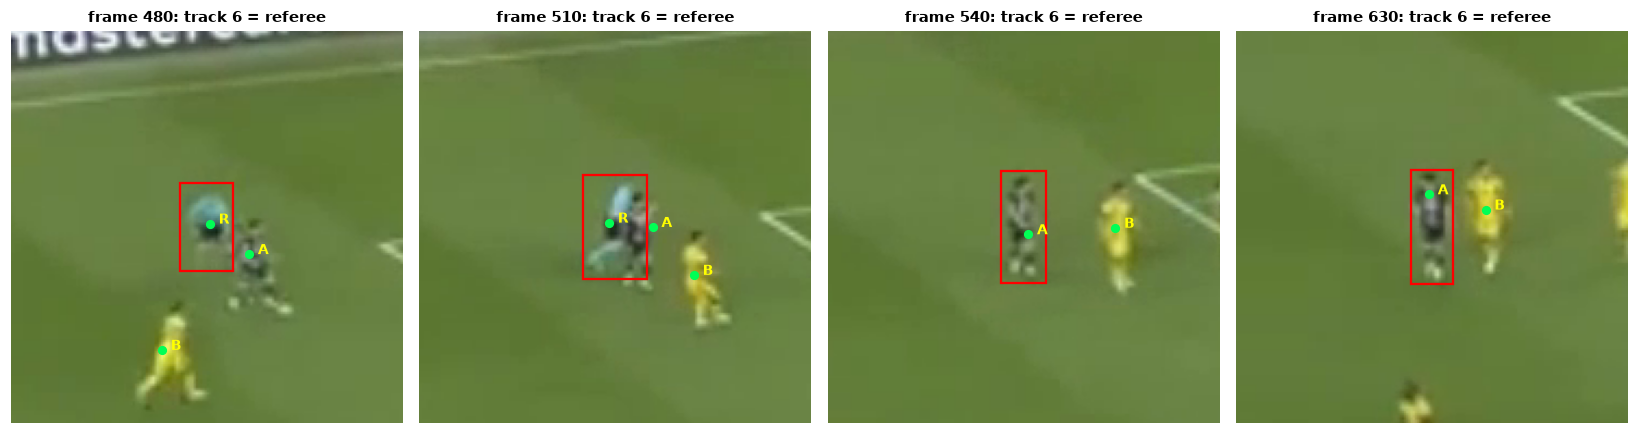

In [25]:
t6 = pd.DataFrame([{"frame": i, "groep": p["group"], "x_m": p["x_m"], "y_m": p["y_m"]} for i in result.ids for p in result.people[i] if p["track_id"] == 6])
print(f"Track 6 bestaat in {len(t6)} frames; groep volgens het systeem: {t6.groep.value_counts().to_dict()}")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, i in zip(axes, (480, 510, 540, 630)):
    p = [q for q in result.people[i] if q["track_id"] == 6][0]
    bx = p["box"]; cx, cy = (bx[0] + bx[2]) / 2, (bx[1] + bx[3]) / 2
    ax.imshow(cv2.cvtColor(read_frame(VIDEO, i), cv2.COLOR_BGR2RGB)); ax.set_xlim(cx - 90, cx + 90); ax.set_ylim(cy + 90, cy - 90); ax.axis("off")
    ax.add_patch(plt.Rectangle((bx[0], bx[1]), bx[2] - bx[0], bx[3] - bx[1], fill=False, ec="red", lw=1.5))
    for g in GT_BODY[i]["persons"]:
        if abs(g["px"][0] - cx) < 90 and abs(g["px"][1] - cy) < 90:
            ax.plot(*g["px"], "o", color="#00ff55", ms=5); ax.text(g["px"][0] + 4, g["px"][1], g["role"], color="yellow", fontsize=9, weight="bold")
    ax.set_title(f"frame {i}: track 6 = {p['group']}", fontsize=10)
plt.tight_layout(); plt.show()

**Wat we zien.** In frame 480 en 510 volgt track 6 de scheidsrechter (lichtblauw shirt). In frame 510 staat hij bijna op een PSG-speler; vanaf frame 540 ligt de box van track 6 op de **PSG-speler** met het donkere shirt, terwijl de groep van de track `referee` blijft. Dat is een **ID-wissel**: de tracker is van de scheidsrechter naar de speler gesprongen, en het systeem geeft een hele track één groep (meerderheidsstem over de track, zie `vote_groups` in `core/tracking.py`), dus de speler wordt als scheidsrechter geteld. Gevolg voor de analyses in notebook 05: die speler telt niet mee voor PSG, en zijn afstand wordt aan "de scheidsrechter" toegerekend.

De rolscore (99,2 %) onderschat dus niet hoe goed het model de klassen herkent (de **detectoren** hebben de speler juist geklassificeerd), maar de koppeling in de tracking laat een fout door. Een herstel zou zijn: de groep per frame kiezen in plaats van per track, of een track splitsen als de klasse van de detecties een tijd afwijkt van de trackgroep.

### 5.4 Balbezit

Zeven van de 28 gelabelde frames zijn fout (6 keer "niemand", 1 keer Inter; de frames 360 en 600 komen in beide sessies voor). Per frame bekijken we de oorzaak: is er een bal, wie staat het dichtst bij en op welke afstand?

,sessie,frame,gelabeld,systeem,oorzaak
0,lichaam,360,PSG,geen,geen bal in dit frame (balbezit vervalt na 15 frames zonder speler bij de bal)
1,lichaam,420,PSG,geen,geen bal in dit frame (balbezit vervalt na 15 frames zonder speler bij de bal)
2,lichaam,570,PSG,Inter,bal (detected) ligt 4.8 m van de dichtstbijzijnde speler (keeper Inter): buiten de straal van 2 m
3,lichaam,600,PSG,geen,bal (interpolated) ligt 4.5 m van de dichtstbijzijnde speler (Inter): buiten de straal van 2 m
4,lichaam,630,PSG,geen,geen bal in dit frame (balbezit vervalt na 15 frames zonder speler bij de bal)
5,voet,360,PSG,geen,geen bal in dit frame (balbezit vervalt na 15 frames zonder speler bij de bal)
6,voet,600,PSG,geen,bal (interpolated) ligt 4.5 m van de dichtstbijzijnde speler (Inter): buiten de straal van 2 m


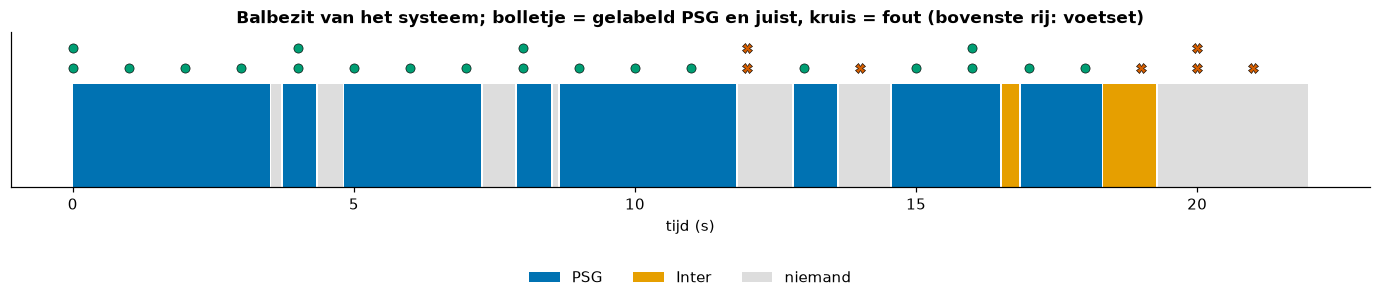

In [26]:
def possession_cause(i):
    ball = result.ball.get(i)
    if ball is None:
        return "geen bal in dit frame (balbezit vervalt na 15 frames zonder speler bij de bal)", None, None
    team_players = [p for p in result.people[i] if p["team"] in ("A", "B")]
    d = [np.hypot(p["x_m"] - ball["x_m"], p["y_m"] - ball["y_m"]) for p in team_players]
    k = int(np.argmin(d))
    who = ROLE_NAME["K" if "goal_keeper" in team_players[k]["group"] else team_players[k]["team"]]
    if d[k] > 2.0:
        return f"bal ({ball['state']}) ligt {d[k]:.1f} m van de dichtstbijzijnde speler ({who}): buiten de straal van 2 m", who, d[k]
    return f"dichtstbijzijnde speler is {who} op {d[k]:.1f} m", who, d[k]

rows = []
for session, gt in SESSIONS.items():
    for i, rec in sorted(gt.items()):
        if preds_poss[i] != rec["possession"]:
            cause, who, dist = possession_cause(i)
            rows.append({"sessie": session, "frame": i, "gelabeld": ROLE_NAME[rec["possession"]], "systeem": ROLE_NAME.get(preds_poss[i], preds_poss[i]), "oorzaak": cause})
poss_errors = pd.DataFrame(rows)
poss_errors.to_csv(OUT / "balbezit_fouten.csv", index=False)
display(poss_errors)

# balbezit in de tijd: systeem tegenover de gelabelde frames
fig, ax = plt.subplots(figsize=(13, 2.2))
t = np.array(result.ids) / result.fps
code_ = {"A": 2, "B": 0, "-": 1}
colors_ = {"A": COL["A"], "B": COL["B"], "-": "#dddddd"}
for team in ("A", "B", "-"):
    mask = np.array([preds_poss[i] == team for i in result.ids])
    ax.fill_between(t, 0, 1, where=mask, step="mid", color=colors_[team], lw=0, label={"A": "PSG", "B": "Inter", "-": "niemand"}[team])
for session, gt in SESSIONS.items():
    for i, rec in gt.items():
        ok = preds_poss[i] == rec["possession"]
        ax.plot(i / result.fps, 1.15 if session == "lichaam" else 1.35, "o" if ok else "X", color=GOOD if ok else BAD, ms=6, mec="black", mew=0.4)
ax.set_yticks([]); ax.set_ylim(0, 1.5); ax.set_xlabel("tijd (s)"); ax.grid(False); fig.set_size_inches(13, 3.2)
ax.set_title("Balbezit van het systeem; bolletje = gelabeld PSG en juist, kruis = fout (bovenste rij: voetset)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.45))
plt.subplots_adjust(bottom=0.42, top=0.86, left=0.04, right=0.99); plt.show()

**Wat we zien.** De balbezitfouten hebben twee oorzaken. In 360, 420 en 630 is er **geen bal**, dus kan het systeem geen bezit toekennen. In 570 en 600 ligt de bal 4,5 tot 4,8 m van de dichtstbijzijnde speler, een Inter-speler of de Inter-keeper, vlak bij het doel: buiten de straal van 2 m, dus "niemand" (600), of via het gladstrijken nog "Inter" (570). Of bezit na een schot nog bij PSG hoort is bovendien een definitiekwestie. Het is dus geen aparte fout in de balbezitregel, maar het gevolg van ontbrekende ballen en van een regel die niet voor het schot bedoeld is.

### 5.5 Overzicht van alle fouten en hun oorzaak

| Fout | Aantal | Oorzaak | Wat zou helpen |
|---|---|---|---|
| Bal gemist | 2 van 21 | bal te klein en onscherp: geen enkele baldetectie | meer trainingsdata met kleine ballen, hogere resolutie rond de bal |
| Bal op verkeerde plek | 1 van 19 gevonden | hoge-zekerheid valse positief (wit vlekje bij een schoen) | temporele controle met de omliggende frames |
| Valse bal | 5 van 7 (4 verschillende frames) | 3 frames met een opgevulde bal, 1 frame met een zwakke detectie (zekerheid 0,26); bij 30, 240 en 270 is op de plek een wit vlekje te zien | strengere interpolatie, betere labels ("bal onzeker") |
| Gemiste speler | 4 van 516 | 3 keer een scheids- of grensrechter op de zijlijn buiten veld plus marge (bewust gefilterd), 1 keer samengevoegd met een buurman | marge groter, of scheidsrechters apart behandelen |
| Extra box | 11 + 3 (voetset) | 5 dubbele boxen op één speler, 4 niet-gelabelde personen aan de rand, 5 naast een klik bij overlappende spelers | duplicaatfilter aanscherpen, labels aanvullen |
| Verkeerde rol | 5 (1 speler) | ID-wissel van scheidsrechter naar PSG-speler | groep per frame, track splitsen |
| Balbezit gemist | 7 van 28 | gevolg van ontbrekende bal of bal in het doel | volgt uit bal |
| Positiefout | gemiddeld 1,09 m | grotendeels systematisch (voeten ~1 m dichter bij de camera dan geklikt) en groter aan de verre kant | voeten-definitie vastleggen, betere homografie ver weg |

De getallen in deze tabel komen uit de cellen hierboven; de tabel zelf is met de hand samengesteld.

## 6. Conclusies

1. **Het systeem vindt de spelers bijna perfect.** F1 = 0,986 (lichaamsset) en 0,989 (voetset); slechts 4 van 516 personen gemist. De resterende extra boxen zijn grotendeels dubbele boxen of niet-gelabelde personen aan de rand.
2. **De positie is op ongeveer 1 m nauwkeurig** (gemiddeld 1,09 m, 90 % binnen 1,77 m). Een groot deel daarvan is een systematische verschuiving (de voet van het systeem ligt dichter bij de camera dan de geklikte voet) en aan de verre kant van het veld is de fout groter omdat een pixel daar meer meters beslaat.
3. **De rol is bij 99,2 % juist**, maar de 5 fouten zijn één echte fout: een ID-wissel waardoor een PSG-speler de scheidsrechterrol erft. Dat is een tracking-probleem, geen detectieprobleem.
4. **De bal is het zwakke punt.** 19 van 21 gelabelde ballen krijgen een positie (18 binnen 3 m), met een mediane fout van 0,2 m wanneer het goed gaat. Twee ballen zijn te klein voor YOLO (geen detectie), één detectie is een valse positief met hoge zekerheid, en het systeem geeft ook ballen waar de labelaar er geen zag (5 van 7), waarvan een deel waarschijnlijk wel een bal is.
5. **De instellingen doen er voor de spelers nauwelijks toe, voor de bal wel**: `imgsz` 1280 vindt 19 ballen, 960 vindt er 15-16, herdetectie voegt er 1 toe, NMS uit kost er 2 en het bal-fine-tune-experiment is niet beter dan het finale model. Baldrempel 0,2 is de hoogste drempel zonder verlies aan gevonden ballen.
6. **De eerder genoemde referentiecijfers kloppen** (F1 0,99, 19/21 ballen, positiefout rond 1 m), met twee preciseringen: de rol is voor het finale model 99,2-99,3 % (100 % vinden we alleen bij het fine-tuned model) en de 0,5 m herkennen we niet als gemiddelde spelersfout (wel als balfout op de voetset, en als spelersfout na aftrek van de systematische verschuiving).

## 7. Beperkingen

- **Weinig gelabelde frames.** 28 frames (22 + 6), waarvan maar 21 met een zichtbare bal en 7 zonder. Eén frame meer of minder verschuift een balpercentage met 5 tot 14 punten. De positiefout rust op 6 frames en 140 punten van één korte periode.
- **Geen onafhankelijke test.** De labelaar is ook de bouwer. De baldrempel (0,2) en `imgsz` (1280) zijn gekozen op dezelfde 21 ballen waarop we ze hier beoordelen. De 19/21 is dus een optimistische schatting voor een nieuwe clip.
- **Labels zijn niet foutloos.** Frame 360 is in de twee sessies tegenstrijdig gelabeld (bal zichtbaar of niet), "niet zichtbaar" staat voor "niet te onderscheiden" en niet voor "afwezig", en een deel van de extra boxen zijn personen die de labelaar niet aanklikte.
- **Twee ankers, twee sessies.** De positiefout komt uit 6 voetframes, de detectie uit 22 lichaamsframes. De lichaamsklik kan geen positiefout in meters geven.
- **De voetpositie is niet scherp gedefinieerd** (onderrand van de box tegenover de klik), dus de absolute positiefout is deels een afspraak.
- **Balbezit is niet te beoordelen.** Alle 28 labels zeggen "PSG"; een systeem dat altijd PSG zegt zou 100 % scoren. Voor een eerlijke meting zijn frames met Inter-balbezit nodig.
- **ID-wissels zijn niet meetbaar.** De gelabelde frames liggen 1 s uit elkaar. De cijfers in de metrics-tabel (71 wissels, IDF1-lite 0,58 voor de lichaamsset; 36 en 0,37 voor de voetset) zeggen daarom meer over de afstand tussen de frames dan over de tracker. Wel zagen we in sectie 5.3 handmatig één ID-wissel. Meten vraagt aaneengesloten gelabelde frames.
- **Eén clip van 22 seconden**, één camerastandpunt, één wedstrijd: de resultaten zeggen niets over andere wedstrijden, belichting of camerahoeken.
- **Het onderscheid met de mAP.** De mAP uit notebook 02 en deze systeemevaluatie meten verschillende dingen en moeten niet met elkaar vergeleken worden.